:::{.callout-note title="AI usage disclosure" collapse="true"}
We used Claude (Opus 4.7) to help write, clean up, and comment our code, to review our code and selectively incorporate its feedback, to suggest wording ideas from which we chose small phrases or sentence structure ideas to use, and to help clarify and streamline text that we wrote.
:::

## Purpose

We spatially and spectrally mapped live cells of *Chlamydomonas reinhardtii* and *Chlamydomonas smithii* at three excitation wavelengths (473, 532, and 785 nm) using two commercial confocal spontaneous Raman systems. Here, we share the analysis notebook used to load, mask, baseline-correct, and decompose the resulting spectral maps. All three datasets captured carotenoid signal, with the 473 nm dataset resolving the most peaks overall and giving the clearest spatial information, due to resonance enhancement, scattering efficiency, and optimized focus. PCA on both unmasked and masked data recovered localized structures consistent with the chloroplast and a smaller eyespot-like feature, while NMF picked up chloroplast-like components. These organelle assignments are tentative.

## Introduction

At Arcadia, we're interested in high-dimensional untargeted phenotyping that can be applied to a wide range of biological samples, from biomolecules to single cells to tissues. To this end, we’ve been using Raman spectroscopy on proteins [@bulow2026protein], algae [@essockburns2025comparison], yeast [@cheveralls2026batch], archaea [@braverman2025diy], and more. We’ve explored two modalities of this technique: spontaneous and coherent. Spontaneous Raman spectroscopy requires one laser and a reasonably simple setup, and is a valuable technique to probe the dynamic chemistry of biological samples. When placed on a microscope, you can do spatially resolved mapping. While coherent Raman microscopy [@bulow2026pombe; @bulow2026cerevisiae] typically offers more spatial resolution and can obtain an image at a single spectral position more quickly, spontaneous Raman microscopy enables an unbiased search for informative spectral peaks across a broad range. The two modalities can be used in a complementary manner: longer full spectral analyses of specific samples, and more targeted spectral searches in higher throughput. 

We have a DIY spontaneous Raman system, two commercial spontaneous Raman systems, and one coherent Raman confocal microscope in-house. To date, we’ve been using the spontaneous systems with simple focusing optics [@braverman2025autoopenraman], though we've also explored adding them to a more complex wide-field microscope. In this study, we had limited access to two commercial confocal spontaneous Raman systems, which enable high-resolution mapping. We acquired data on samples of living *Chlamydomonas reinhardtii* and *Chlamydomonas smithii* cells. We tested three excitation wavelengths: 473 nm, 532 nm, and 785 nm. Here, we share an analysis notebook that we used to visualize and analyze spectral and map data from both commercial systems. Our intent was to explore the types of scientific questions that could be enabled with this combination of spatial and spectral information on biological samples. 

We hope the notebook will be helpful to biologists interested in different types of spontaneous Raman microscopy for their samples, and to anyone interested in visualizing spectral map data from these commercial systems.

:::{.callout-note}
## Accessing the code, data, and environment

The analysis notebook, raw spectral data, and rendered publication source are available at the [GitHub repository](https://github.com/Arcadia-Science/raman-mapping-algae). The `data/` folder contains the raw `.txt` and `.tsv` files used in this analysis, and `env.yml` specifies the conda environment. See the [Reproduce this pub](pages/SETUP.qmd) page for cloning and setup instructions.
:::  

## Background

In this study, we looked at the chemistry of single wild-type *Chlamydomonas* cells with three different excitation wavelengths. *Chlamydomonas reinhardtii* and *Chlamydomonas smithii* are two species of interest for Arcadia Science and have been part of our organism selection efforts [@avasthi2024evolution]. *Chlamydomonas* is a genus of unicellular green algae that are photosynthetic, have flagella, and are about 10 μm in size [@harris2001chlamydomonas]. Both species have strong structural and compositional similarities; *C. reinhardtii* is the more common model organism. Prior work involving Raman spectroscopy of this genus demonstrates that it can be used to detect light-harvesting pigments chlorophyll and carotenoids under different stress conditions [@pandey2022microraman], lipid content and saturation [@sharma2015lipid], starch content [@ji2014starch], and lipid/carbohydrate ratio [@chiu2017lipidstarch]. 


Specific organelles in the *Chlamydomonas* cell should give distinct and localized spectral signals based on their composition. For instance, chloroplasts should show clear pigment peaks (chlorophyll and carotenoids) in a cup-shaped formation; the eyespot should appear as strong carotenoid peaks concentrated on the side of the chloroplast, and starch granules may be detectable at different places in the cell body [@harris2001chlamydomonas]. What can be resolved depends on both the spectral content and on the imaging configuration: beam size, step size, objective magnification, and numerical aperture together set the spatial resolution achievable on the map.

The excitation wavelength matters because light of different energies interacts with samples differently. Scattering efficiency decreases as wavelength increases, so the same compound may produce weaker peaks under 785 nm than 532 nm. Near-infrared wavelengths can also avoid the background fluorescence common from biological samples at other wavelengths. Resonance enhancement is a separate effect: when the excitation wavelength overlaps the molecule's absorption band, the Raman signal from that molecule can be orders of magnitude stronger. Carotenoids, for example, absorb between 450–520 nm, so they're resonantly enhanced at 473, and to a lesser degree, at 532 nm excitation (@fig-schematic).

In this study, our goals were to:

* Evaluate whether we could use spontaneous Raman mapping to detect distinct biological structures (e.g., chloroplast).
* Understand which excitation wavelength yielded the most resolvable features, whether they had complementary information, and the pros and cons of each.
* Explore data analysis methods useful for spatially resolved Raman data.

![Schematic of *Chlamydomonas* cellular components potentially detectable by Raman spectroscopy (top), with UV-Vis absorbance spectra of pigment standards and the three Raman excitation wavelengths overlaid (bottom). Overlap between an excitation line and a pigment absorption suggests resonance enhancement of that pigment's Raman signal.](./assets/final_fig1.png){#fig-schematic fig-alt="Schematic illustration of Chlamydomonas cellular components (chloroplast, eyespot, starch granules, flagella, nucleus) above UV-Vis absorbance spectra of carotenoid and chlorophyll standards with the three Raman excitation wavelengths (473, 532, 785 nm) marked." width=800}


## Caveats

Our aim was to evaluate the instruments and analysis methods for cell biology investigations, rather than conduct a controlled scientific investigation. Therefore, there are significant caveats to this dataset that preclude drawing strong scientific claims. We used the same species for the 473 nm and 532 nm excitation acquisitions, which were acquired on the same instrument on the same day. However, the focusing in z was different between the two acquisitions and they were on different cell clusters. The 785 nm data was acquired on a different instrument and species, on a different day, and we focused on a single cell rather than a cluster. Given that our interest was single-cell analysis to evaluate subcellular structure, we did detailed scans on few cells overall, so there is a low n. We also did not perform this on biological or technical replicates or across days.

## Sample prep

We purchased commercial pigment standards for UV-vis spectrophotometry: β-carotene (VWR cat. AAH60106-03, 99%), lycopene (VWR cat. 76838-342, ≥98.0%), chlorophyll a (Millipore Sigma cat. C6144-1MG, from *Anacystis nidulans* algae), and chlorophyll b (Millipore Sigma cat. 00538-1MG, ≥95.0%). We created solutions in acetone (100%), diluting as needed to avoid saturating the detector, and analyzed them in PMMA cuvettes. 

We grew two wild-type strains of *Chlamydomonas* (*C. reinhardtii* CC-124, mating type −, and *C. smithii* CC-1373) in a lawn on TAP (tris-acetate-phosphate) medium (UTEX) with 1.5% agar at room temperature, in a 12/12 h light–dark cycle. We prepared the samples for microscopy as described [here](https://research.arcadiascience.com/pub/perspective-raman-spec-comparison/release/1/). 

## Instrumentation

We used three different instruments for this study:

* NanoDrop OneC, a spectrophotometer with a cuvette configuration, to collect the UV-visible spectra. The instrument has a wavelength range of 190–850 nm and an accuracy of ±1 nm. More information about the system is [here](https://www.thermofisher.com/us/en/home/industrial/spectroscopy-elemental-isotope-analysis/molecular-spectroscopy/uv-vis-spectrophotometry/instruments/nanodrop/instruments/nanodro-one.html).

* Horiba LabRAM Evolution, a confocal spontaneous Raman system, to collect Raman spectra on cells on a glass slide with coverslip. This system has two different stages; we used the mapping stage with the optical microscope, 100× air objective, and 473 nm and 532 nm excitation. We used the following parameters for all samples: 0.4 s exposure, 50 accumulations, and a 300 grooves/mm grating. The laser power was 1.3 mW at 473 nm and 1.74 mW at 532 nm. More information about the system can be found [here](https://www.horiba.com/usa/scientific/products/detail/action/show/Product/labram-hr-evolution-1083/). We centered on a group of four CC-124 cells grown on TAP medium and mapped them with a confocal beam size of ~1 μm and a step size of ~0.5 μm. Because the step size is smaller than the beam, adjacent points overlap and the map is oversampled. This instrument was operated by Andrey Krayev in Novato, CA. 

* Renishaw inVia Qontor, a confocal spontaneous Raman system with a mapping stage, to collect Raman spectra on cells on a glass slide with coverslip. We used a 50× LWD Leica air objective, 785 nm excitation at 10% power setting (16.3 mW at the sample), and the following parameters for all samples: 1 s exposure, one accumulation, and a 1200 grooves/mm grating. More information about the system can be found [here](https://www.renishaw.com/en/invia-confocal-raman-microscope--6260?srsltid=AfmBOoqq5Ys7ZKGPdvcMO7uoD1bW5XOo6ujQAsnAE0KLmAW0v7nQUPhF). We centered on a single CC-1373 cell and mapped it with a beam size of ~2 μm. This instrument was operated by Sarah Shidler in Berkeley, CA.

## UV-Vis absorbance of pigment standards

The pigment absorbance spectra show where each molecule absorbs light most strongly, which informs where resonance Raman enhancement may occur (@fig-uvvis-all). Carotenoids (β-carotene, lycopene) absorb broadly between ~420–520 nm, with peak absorption near 450–480 nm. Both the 473 nm and 532 nm laser lines fall within or near this window, predicting resonance enhancement of carotenoid Raman signals under both excitation wavelengths. The 473 nm line sits closer to the β-carotene absorption maximum, suggesting potentially stronger enhancement. Chlorophylls a and b have Soret absorption bands near 430–435 nm and Q-band absorption near 640–680 nm [@croce2000soret]. None of the three excitation wavelengths closely overlap these transitions, so chlorophyll peaks are not expected to be resonantly enhanced. The 785 nm laser is well outside the absorption bands of all four pigments, so all Raman signals at this wavelength reflect non-resonant scattering and are expected to be weaker relative to carotenoid signals seen at the shorter wavelengths.

In [21]:
# | code-fold: true
# | code-summary: "Source code for this figure:"
# | label: fig-uvvis-all
# | fig-cap: "UV-Vis absorbance spectra of β-carotene, lycopene, chlorophyll a, and chlorophyll b standards dissolved in acetone. Click-and-drag or use the Plotly toolbar to zoom into specific wavelength ranges or peaks."
# | fig-alt: "UV-Vis absorbance spectra of β-carotene, lycopene, chlorophyll a, and chlorophyll b standards in acetone; x-axis wavelength in nm, y-axis absorbance."

import arcadia_pycolor as apc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import scipy.signal
from matplotlib.colors import ListedColormap
from plotly.subplots import make_subplots
from pybaselines.whittaker import airpls
from sklearn.decomposition import NMF, PCA

apc.plotly.setup()
apc.mpl.setup()
import matplotlib_inline

matplotlib_inline.backend_inline.set_matplotlib_formats("retina")
plt.rcParams["savefig.dpi"] = 300

# Format matplotlib axis tick labels with thousands separators (e.g. 1,000).
import locale

locale.setlocale(locale.LC_ALL, "en_US.UTF-8")
plt.rcParams["axes.formatter.use_locale"] = True

# Configure Plotly to emit both the JSON mimetype and HTML representation.
# Quarto needs the HTML version to render figures when the notebook is
# executed via nbconvert (otherwise Plotly emits JSON-only).
import plotly.io as pio

pio.renderers.default = "plotly_mimetype+notebook_connected"


# Step 1: Read the TSV manually
def import_tsv(file_path):
    with open(file_path) as f:
        lines = [line.strip().split("\t") for line in f if line.strip()]
    df = pd.DataFrame(lines)
    return df


# Step 2: Extract sample blocks and names
def split_uv_vis_data(df):
    split_indices = df.index[df.iloc[:, 0] == "Wavelength (nm)"].tolist()
    split_dfs = []
    labels = []

    for i in range(len(split_indices)):
        header_idx = split_indices[i]
        sample_name = df.iloc[header_idx - 2, 0]  # sample name is two rows above header
        start_idx = header_idx + 1
        end_idx = split_indices[i + 1] - 3 if i + 1 < len(split_indices) else len(df)

        headers = df.iloc[header_idx]
        data = df.iloc[start_idx : end_idx + 1].copy()
        data.columns = headers
        split_dfs.append(data)
        labels.append(sample_name)

    return split_dfs, labels


# Step 3a: Combined plot with Plotly
def plot_all_spectra_plotly(dfs, labels):
    fig = go.Figure()
    for df, label in zip(dfs, labels, strict=False):
        df = df.dropna()
        df = df.apply(pd.to_numeric, errors="coerce")
        fig.add_trace(
            go.Scatter(
                x=df["Wavelength (nm)"],
                y=df.iloc[:, 1],
                mode="lines",
                name=label,
            )
        )

    fig.update_layout(
        xaxis_title="Wavelength (nm)",
        yaxis_title="Absorbance",
        xaxis_range=[350, 800],
        paper_bgcolor=apc.parchment,
        plot_bgcolor=apc.parchment,
        width=800,
        height=400,
    )
    apc.plotly.style_plot(fig, monospaced_axes="xy")
    fig.show()


# ---- Main Execution ----
file_path = "data/UV-Vis 5_1_2025 7_19_21 PM.tsv"
uv_vis_raw = import_tsv(file_path)
split_uv_vis, sample_labels = split_uv_vis_data(uv_vis_raw)

plot_all_spectra_plotly(split_uv_vis, sample_labels)

## Raman microscopy of live *Chlamydomonas* cells

Each dataset we acquired contained spectral data across a range of wavenumbers and xy positional data. 

### Initial spectral plot comparison

First, let's plot the data from each experiment individually (@fig-473-all). We can visually identify similarities and differences between the spectra and find specific Raman shift values that could be biological markers.

We'll start with 473 nm data from the Horiba LabRAM Evolution. This map has 1,073 points and covers four cells and white space between and around them. We can apply a gentle median filter to remove some of the noise, which can arise from detector noise or cosmic rays. Each figure in this section has median-filtered Raman data (kernel size = 5). 

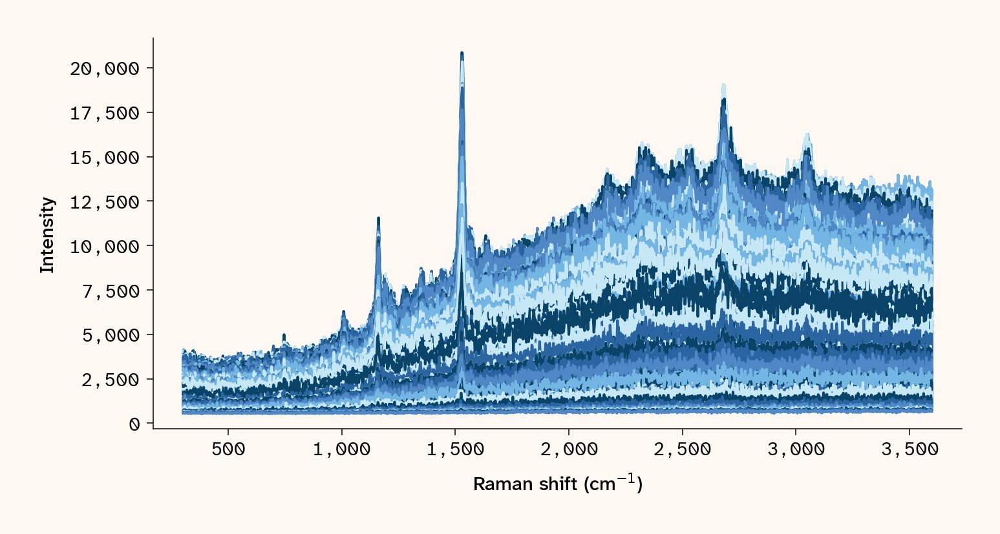

In [22]:
# | code-fold: true
# | code-summary: "Source code for this figure:"
# | label: fig-473-all
# | fig-cap: "1,073 raw Raman spectra (one per map point) of *Chlamydomonas reinhardtii* CC-124 cells with 473 nm excitation, prior to baseline correction or masking."
# | fig-alt: "Overlaid line plot of 1,073 Raman spectra from the 473 nm dataset of *C. reinhardtii* cells; x-axis Raman shift in cm⁻¹, y-axis intensity."

# Load Horiba 473 data

blue_path = "data/Cells- 473nm-Map-ForPeng 1.txt"
blue_data = pd.read_csv(blue_path, sep="\t")

# Rename first two columns to x and y positions

blue_data = blue_data.rename(columns={"Unnamed: 0": "x_pos", "Unnamed: 1": "y_pos"})

# Separate the data into two dataframes, one for xy positions and one for intensity values

blue_xy = blue_data[["x_pos", "y_pos"]]
blue_intensity = blue_data.drop(columns=["x_pos", "y_pos"])
blue_num_points = len(blue_xy)

# Flip the intensity dataframe horizontally and convert column names to float

blue_intensity = blue_intensity.iloc[:, ::-1]
blue_intensity.columns = blue_intensity.columns.astype(float)

# Crop the intensity data to only include Raman shifts between 300 and 3600 cm-1

blue_intensity = blue_intensity.loc[
    :, (blue_intensity.columns >= 300) & (blue_intensity.columns <= 3600)
]

# Apply a median filter to the intensity data

blue_intensity_filt = blue_intensity.apply(lambda x: scipy.signal.medfilt(x, kernel_size=5))

# Plot spectra in blue_intensity_filt using matplotlib

fig, ax = plt.subplots(
    figsize=(10, 5),
    constrained_layout=True,
    # dpi=300,
    facecolor=apc.parchment,
)
colors = apc.palettes.blue_shades.colors
for i in range(len(blue_intensity_filt)):
    ax.plot(
        blue_intensity_filt.columns,
        blue_intensity_filt.iloc[i],
        label=f"Point {i + 1}",
        color=colors[i % len(colors)],
    )
ax.set_xlabel("Raman shift (cm$^{-1}$)")
ax.set_ylabel("Intensity")
apc.mpl.style_plot(monospaced_axes="both")
ax.set_facecolor(apc.parchment)

plt.show()

The most intense peaks are at ~1157, ~1530, and ~2650 cm^-1^. Some spectra have minor peaks at ~1005, between 2200-2500, and ~3100 cm^-1^. Even with no baseline removal applied to the spectra, there's only a bit of fluorescence, which causes the baseline to rise. It's also apparent that some points have no signal, which is expected given that many positions didn't hit a cell. 

Let's make a similar plot with the 532 nm data from the Horiba LabRAM Evolution on another group of cells from the same slide, with a differently sized map of 837 points (@fig-532-all).

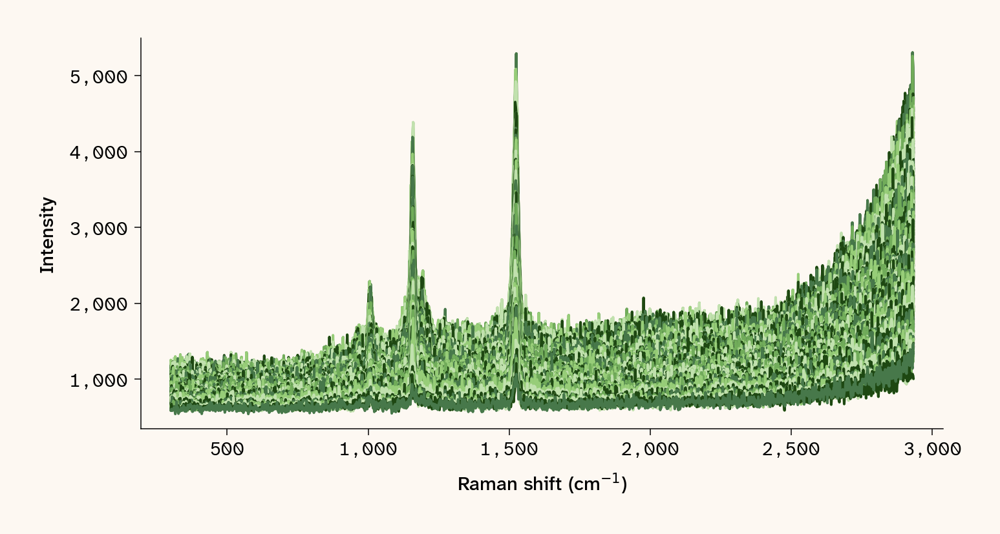

In [23]:
# | code-fold: true
# | code-summary: "Source code for this figure:"
# | label: fig-532-all
# | fig-cap: "837 raw Raman spectra (one per map point) of *Chlamydomonas reinhardtii* CC-124 cells with 532 nm excitation, prior to baseline correction or masking."
# | fig-alt: "Overlaid line plot of 837 Raman spectra from the 532 nm dataset of *C. reinhardtii* cells; x-axis Raman shift in cm⁻¹, y-axis intensity."

# Load Horiba 532 data

green_path = "data/Cells- 532nm-Map-ForPeng 1.txt"
green_data = pd.read_csv(green_path, sep="\t")

# Rename first two columns to x and y positions

green_data = green_data.rename(columns={"Unnamed: 0": "x_pos", "Unnamed: 1": "y_pos"})

# Separate the data into two dataframes, one for xy positions and one for intensity values

green_xy = green_data[["x_pos", "y_pos"]]
green_intensity = green_data.drop(columns=["x_pos", "y_pos"])
green_num_points = len(green_xy)

# Flip the intensity dataframe horizontally and convert column names to float

green_intensity = green_intensity.iloc[:, ::-1]
green_intensity.columns = green_intensity.columns.astype(float)

# Crop the intensity data to only include Raman shifts between 300 and 3600 cm-1

green_intensity = green_intensity.loc[
    :, (green_intensity.columns >= 300) & (green_intensity.columns <= 3600)
]

# Apply a median filter to the intensity data

green_intensity_filt = green_intensity.apply(lambda x: scipy.signal.medfilt(x, kernel_size=5))

# Plot spectra in green_intensity using matplotlib; x values are the header row of green_intensity

fig, ax = plt.subplots(
    figsize=(10, 5),
    constrained_layout=True,
    # dpi=300,
    facecolor=apc.parchment,
)
colors = apc.palettes.green_shades.colors
for i in range(len(green_intensity_filt)):
    ax.plot(
        green_intensity_filt.columns,
        green_intensity_filt.iloc[i],
        label=f"Point {i + 1}",
        color=colors[i % len(colors)],
    )
ax.set_xlabel("Raman shift (cm$^{-1}$)")
ax.set_ylabel("Intensity")
apc.mpl.style_plot(monospaced_axes="both")
ax.set_facecolor(apc.parchment)

plt.show()

Looking at the spectra, the most intense peaks are at ~1005, ~1157, and ~1530 cm^-1^. Minor peaks are hard to discern, though there's possibly a shoulder on the 1157 peak. Fluorescence in this case appears at the tail end of the spectra, increasing beyond 2500 cm^-1^. 

Let's make a similar plot with the 785 nm data from the Renishaw inVia Qontor (@fig-785-all). In this case, we mapped a single *C. smithii* CC-1373 cell with a more limited spectral range for a quicker acquisition. 

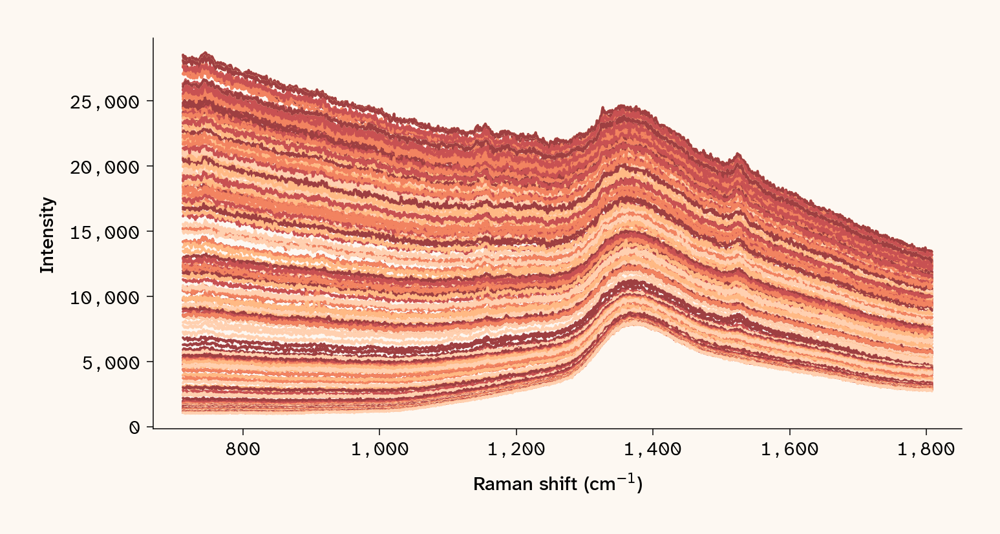

In [24]:
# | code-fold: true
# | code-summary: "Source code for this figure:"
# | label: fig-785-all
# | fig-cap: "285 raw Raman spectra (one per map point) of *Chlamydomonas smithii* CC-1373 with 785 nm excitation, prior to baseline correction or masking."
# | fig-alt: "Overlaid line plot of 285 Raman spectra from the 785 nm dataset of *C. smithii* CC-1373; x-axis Raman shift in cm⁻¹, y-axis intensity."

# Load Renishaw 785 data - LONG FORMAT
red_path = "data/2024-11-12_CC-1373_TAP_slide_10_singlecellmap.txt"

# Read with only the first 4 columns (X, Y, Wave, Intensity)
df = pd.read_csv(
    red_path, sep="\t", usecols=[0, 1, 2, 3], names=["X", "Y", "Wave", "Intensity"], skiprows=1
)

# Get unique Raman shifts
raman_shifts = sorted(df["Wave"].unique())

# Pivot to wide format: rows = spatial points, columns = Raman shifts
data_wide = df.pivot_table(index=["X", "Y"], columns="Wave", values="Intensity", aggfunc="first")
data_wide = data_wide.reset_index()

# Extract spatial positions AFTER pivoting to ensure correct order
red_xy = data_wide[["X", "Y"]].copy()
red_num_points = len(red_xy)

# Extract intensity columns
red_intensity_restructured = data_wide.drop(columns=["X", "Y"])
red_intensity_restructured.columns = red_intensity_restructured.columns.astype(float)

# Flip to match Horiba orientation (high to low wavenumber)
red_intensity_restructured = red_intensity_restructured.iloc[:, ::-1]

# Apply a median filter to the intensity data
red_intensity_filt = red_intensity_restructured.apply(
    lambda x: scipy.signal.medfilt(x, kernel_size=5)
)

# Plot spectra using matplotlib
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True, facecolor=apc.parchment)
colors = apc.palettes.red_shades.colors
for i in range(len(red_intensity_filt)):
    ax.plot(
        red_intensity_filt.columns,
        red_intensity_filt.iloc[i],
        label=f"Point {i + 1}",
        color=colors[i % len(colors)],
    )
ax.set_xlabel("Raman shift (cm$^{-1}$)")
ax.set_ylabel("Intensity")
apc.mpl.style_plot(monospaced_axes="both")
ax.set_facecolor(apc.parchment)

plt.show()

Looking at the 785 spectra, there's a bump around 1400 cm^-1^ due to the light interacting with the glass slide [@fikiet2019glass]. You can still see peaks at ~1157 and ~1530 cm^-1^, though they may be less intense than in the other wavelengths.  

Even without applying baseline correction or normalization, it's clear that there are definitive Raman peaks in every dataset. Across all three wavelengths, we see some common peaks at ~1157 and 1530 cm^-1^. This combination matches well with C–C stretching and C=C stretching modes of carotenoids, which would be expected in photosynthetic algae [@pandey2022microraman]. The 473 nm spectra have the greatest number of peaks distinguishable by eye, followed by 532 nm and then 785 nm. This is consistent with carotenoid resonance enhancement, since carotenoids absorb 473 nm light well (@fig-schematic), which boosts their signal relative to the longer wavelengths.

### Initial spectral map comparison

To better explore the data and find spatial hot spots, we can present the data differently. Each file contains x, y positional data for the point at which a spectrum was taken, which can be plotted to generate spatial maps colored by intensity at each wavenumber. The 473 nm map is shown here as an interactive figure (@fig-473spectralmap), letting you scroll through the Raman shift axis to view the intensity distribution at each wavenumber. For 532 nm (@fig-532spectralmap) and 785 nm (@fig-785spectralmap), the rendered pub shows a static slice at the carotenoid ν₁ peak (~1530 cm⁻¹); the full interactive versions are saved locally when the notebook is executed.
The size of the points in the plot doesn't reflect the beam size of the spectrometer, and the spacing isn't to scale.

In [25]:
# | code-fold: true
# | code-summary: "Source code for this figure:"
# | label: fig-473spectralmap
# | fig-cap: "Interactive spectral map (top) and mean spectrum (bottom) of *Chlamydomonas reinhardtii* CC-124 cells under 473 nm excitation. Use the slider to view the spatial intensity distribution at different wavenumbers; the vertical line on the spectrum marks the current wavenumber. Click-and-drag or use the Plotly toolbar to zoom into specific peaks or traces."
# | fig-alt: "Interactive spectral map (top) and mean spectrum (bottom) of *Chlamydomonas reinhardtii* CC-124 cells under 473 nm excitation; the slider controls the wavenumber displayed on the map."

with open(blue_path) as f:
    header_line = f.readline().strip().split()
raman_shifts = [float(val) for val in header_line]

data = pd.read_csv(blue_path, sep=r"\s+", skiprows=1, header=None)
data = data.rename(columns={0: "x", 1: "y"})

# Rename intensity columns to match raman_shifts
intensity_columns = {i + 2: raman_shifts[i] for i in range(len(raman_shifts))}
data = data.rename(columns=intensity_columns)

# Crop to fingerprint + high-wavenumber region
allowed_cols = [s for s in raman_shifts if 300 <= s <= 3600]

df_long = data.melt(
    id_vars=["x", "y"], value_vars=allowed_cols, var_name="raman_shift", value_name="intensity"
)
df_long["raman_shift"] = df_long["raman_shift"].astype(float)
df_long["intensity"] = pd.to_numeric(df_long["intensity"], errors="coerce")
df_long = df_long.sort_values(by="raman_shift")

mean_spec = df_long.groupby("raman_shift", as_index=False)["intensity"].mean()
unique_shifts = sorted(df_long["raman_shift"].unique())
# Subsample to every 5th frame to keep the embedded notebook output under GitHub's 100 MB limit
unique_shifts = unique_shifts[::5]

# Convert colorscale once, not per frame, for performance
magma_colorscale = apc.gradients.magma.to_plotly_colorscale()

# Two-row figure: spatial map on top, mean spectrum below
fig = make_subplots(rows=2, cols=1, row_heights=[0.65, 0.35], vertical_spacing=0.15)

x_full = data["x"]
y_full = data["y"]

# Initial frame
init_shift = unique_shifts[0]
init_col = init_shift
intensity_init = data[init_col]

map_trace = go.Scatter(
    x=x_full,
    y=y_full,
    mode="markers",
    marker=dict(
        size=10,
        color=intensity_init,
        colorscale=magma_colorscale,
        colorbar=dict(title=dict(text="Intensity"), tickfont=dict(color="black")),
    ),
    name="Spectral map of <i>Chlamydomonas</i> cells (473 nm)",
)
fig.add_trace(map_trace, row=1, col=1)

mean_trace = go.Scatter(
    x=mean_spec["raman_shift"],
    y=mean_spec["intensity"],
    mode="lines",
    line=dict(color="black"),
    name="Mean spectrum",
)
fig.add_trace(mean_trace, row=2, col=1)

# Vertical indicator line on mean spectrum at current shift
if init_shift != 0:
    init_line = dict(
        type="line",
        x0=init_shift,
        x1=init_shift,
        y0=mean_spec["intensity"].min(),
        y1=mean_spec["intensity"].max(),
        line=dict(color="black", width=2),
        opacity=0.5,
        xref="x2",
        yref="y2",
    )
    fig.update_layout(shapes=[init_line])

# Animation frames
frames = []
for shift in unique_shifts:
    intensity_vals = data[shift]
    shapes_list = []
    if shift != 0:
        shapes_list = [
            dict(
                type="line",
                x0=shift,
                x1=shift,
                y0=mean_spec["intensity"].min(),
                y1=mean_spec["intensity"].max(),
                line=dict(color="black", width=2),
                opacity=0.5,
                xref="x2",
                yref="y2",
            )
        ]
    frame = go.Frame(
        data=[
            go.Scatter(
                x=x_full, y=y_full, marker=dict(color=intensity_vals, colorscale=magma_colorscale)
            ),
            go.Scatter(
                x=mean_spec["raman_shift"],
                y=mean_spec["intensity"],
                mode="lines",
                line=dict(color="black"),
            ),
        ],
        layout=dict(shapes=shapes_list),
        name=str(shift),
    )
    frames.append(frame)
fig.frames = frames

# Slider
slider_steps = []
for shift in unique_shifts:
    step = dict(
        method="animate",
        args=[
            [str(shift)],
            dict(
                mode="immediate", frame=dict(duration=100, redraw=True), transition=dict(duration=0)
            ),
        ],
        label=str(round(shift, 1)),
    )
    slider_steps.append(step)

fig.update_layout(
    sliders=[
        dict(
            active=0,
            currentvalue=dict(prefix="Raman shift (cm⁻¹): "),
            pad={"t": 10},
            steps=slider_steps,
            x=0,
            y=-0.1,
            len=1,
        )
    ],
    width=800,
    height=800,
    showlegend=False,
    plot_bgcolor="black",
    paper_bgcolor="#FDF8F2",
    font=dict(family="Helvetica Neue", color="black"),
)

# Spatial map axes (row 1)
x_min = data["x"].min()
x_max = data["x"].max()
y_min = data["y"].min()
y_max = data["y"].max()

fig.update_xaxes(
    row=1,
    col=1,
    showgrid=False,
    showline=True,
    linewidth=1,
    linecolor="black",
    title="X (μm)",
    range=[x_min, x_max],
)
fig.update_yaxes(
    row=1,
    col=1,
    showgrid=False,
    showline=True,
    linewidth=1,
    linecolor="black",
    title="Y (μm)",
    range=[y_min, y_max],
)

# Mean spectrum axes (row 2)
fig.update_xaxes(
    row=2,
    col=1,
    showgrid=False,
    showline=True,
    linewidth=1,
    linecolor="black",
    title="Raman shift (cm⁻¹)",
)
fig.update_yaxes(
    row=2,
    col=1,
    showgrid=False,
    showline=True,
    linewidth=1,
    linecolor="black",
    title="Mean intensity",
)

fig.update_xaxes(row=1, col=1, scaleanchor="y", scaleratio=1)

# Plotly doesn't support per-subplot bg color, so add a rectangle behind row 2
x2_domain = fig.layout.xaxis2.domain
y2_domain = fig.layout.yaxis2.domain
fig.add_shape(
    type="rect",
    xref="paper",
    yref="paper",
    x0=x2_domain[0],
    x1=x2_domain[1],
    y0=y2_domain[0],
    y1=y2_domain[1] + 0.02,
    fillcolor="#FDF8F2",
    layer="below",
    line_width=0,
)

apc.plotly.style_plot(fig, monospaced_axes="all")
apc.plotly.style_legend(fig)
apc.plotly.add_commas_to_axis_tick_labels(fig)
fig.show()

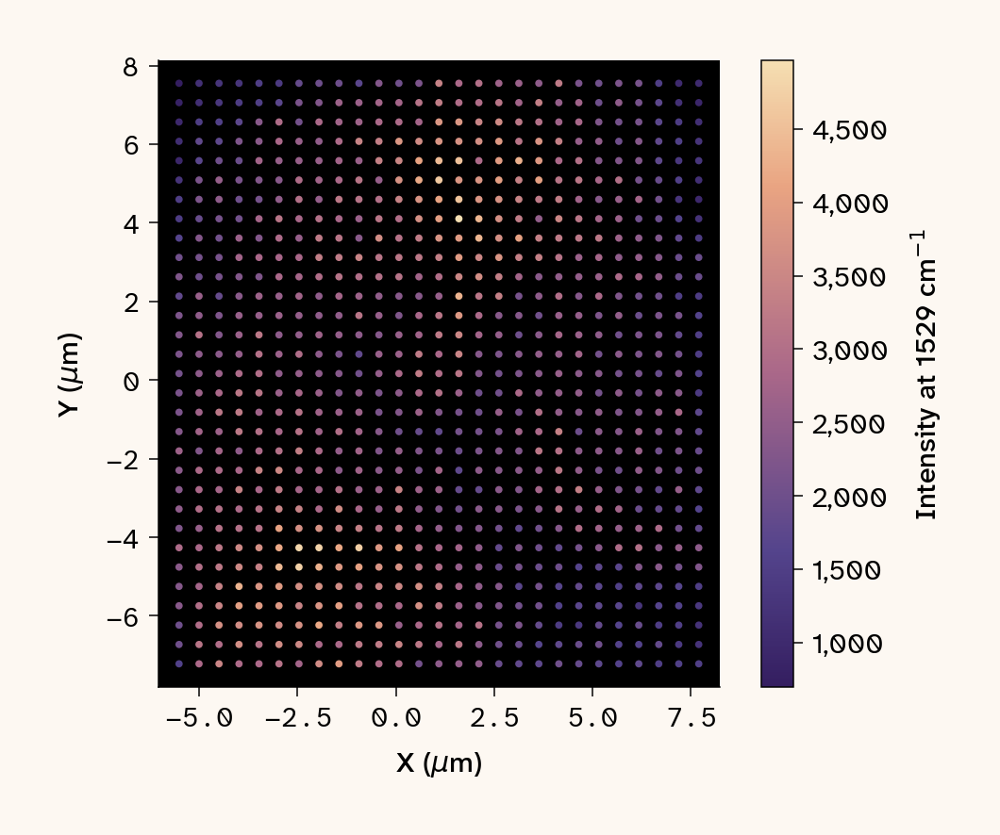

In [26]:
# | code-fold: true
# | code-summary: "Source code for this figure:"
# | label: fig-532spectralmap
# | fig-cap: "Spatial intensity map of *Chlamydomonas reinhardtii* CC-124 cells under 532 nm excitation, at the carotenoid ν₁ peak (~1530 cm⁻¹)."
# | fig-alt: "Static spatial intensity map of *Chlamydomonas reinhardtii* CC-124 cells at the carotenoid ν₁ peak (~1530 cm⁻¹), 532 nm excitation, black background, magma colorscale."

import os

with open(green_path) as f:
    header_line = f.readline().strip().split()
raman_shifts = [float(val) for val in header_line]

data = pd.read_csv(green_path, sep=r"\s+", skiprows=1, header=None)
data = data.rename(columns={0: "x", 1: "y"})
intensity_columns = {i + 2: raman_shifts[i] for i in range(len(raman_shifts))}
data = data.rename(columns=intensity_columns)

allowed_cols = [s for s in raman_shifts if 300 <= s <= 3600]

# Build the interactive Plotly version once and save as standalone HTML.
# Skipped on subsequent runs if the backup file already exists.
backup_path = "assets/532nm_interactive_spectralmap.html"
if not os.path.exists(backup_path):
    df_long = data.melt(
        id_vars=["x", "y"], value_vars=allowed_cols, var_name="raman_shift", value_name="intensity"
    )
    df_long["raman_shift"] = df_long["raman_shift"].astype(float)
    df_long["intensity"] = pd.to_numeric(df_long["intensity"], errors="coerce")
    df_long = df_long.sort_values(by="raman_shift")
    mean_spec = df_long.groupby("raman_shift", as_index=False)["intensity"].mean()
    unique_shifts = sorted(df_long["raman_shift"].unique())
    magma_colorscale = apc.gradients.magma.to_plotly_colorscale()

    fig_i = make_subplots(rows=2, cols=1, row_heights=[0.65, 0.35], vertical_spacing=0.15)
    init_shift = unique_shifts[0]
    fig_i.add_trace(
        go.Scatter(
            x=data["x"],
            y=data["y"],
            mode="markers",
            marker=dict(
                size=10,
                color=data[init_shift],
                colorscale=magma_colorscale,
                colorbar=dict(title=dict(text="Intensity")),
            ),
        ),
        row=1,
        col=1,
    )
    fig_i.add_trace(
        go.Scatter(
            x=mean_spec["raman_shift"],
            y=mean_spec["intensity"],
            mode="lines",
            line=dict(color="black"),
        ),
        row=2,
        col=1,
    )
    frames = []
    for shift in unique_shifts:
        frames.append(
            go.Frame(
                data=[
                    go.Scatter(
                        x=data["x"],
                        y=data["y"],
                        marker=dict(color=data[shift], colorscale=magma_colorscale),
                    ),
                    go.Scatter(x=mean_spec["raman_shift"], y=mean_spec["intensity"], mode="lines"),
                ],
                layout=dict(
                    shapes=[
                        dict(
                            type="line",
                            x0=shift,
                            x1=shift,
                            y0=mean_spec["intensity"].min(),
                            y1=mean_spec["intensity"].max(),
                            xref="x2",
                            yref="y2",
                            line=dict(color="black", width=2),
                            opacity=0.5,
                        )
                    ]
                ),
                name=str(shift),
            )
        )
    fig_i.frames = frames
    slider_steps = [
        dict(
            method="animate",
            args=[
                [str(s)],
                dict(
                    mode="immediate",
                    frame=dict(duration=100, redraw=True),
                    transition=dict(duration=0),
                ),
            ],
            label=str(round(s, 1)),
        )
        for s in unique_shifts
    ]
    fig_i.update_layout(
        sliders=[
            dict(
                active=0,
                currentvalue=dict(prefix="Raman shift (cm⁻¹): "),
                pad={"t": 10},
                steps=slider_steps,
                x=0,
                y=-0.1,
                len=1,
            )
        ],
        width=800,
        height=1200,
        showlegend=False,
        plot_bgcolor="black",
        paper_bgcolor="#FDF8F2",
        font=dict(family="Helvetica Neue", color="black"),
    )
    fig_i.write_html(backup_path, include_plotlyjs="cdn")

# Static spatial map at the 1530 cm⁻¹ carotenoid peak (what is shown in the rendered pub).
target_wn = 1530
idx_1530 = int(np.argmin(np.abs(np.array(allowed_cols) - target_wn)))
actual_wn = allowed_cols[idx_1530]
intensities = data[actual_wn]

fig, ax = plt.subplots(figsize=(8, 6), facecolor=apc.parchment)
sc = ax.scatter(data["x"], data["y"], c=intensities, cmap=apc.gradients.magma.to_mpl_cmap(), s=15)
plt.colorbar(sc, ax=ax, label=f"Intensity at {actual_wn:.0f} cm$^{{-1}}$")
ax.set_xlabel("X ($\\mu$m)")
ax.set_ylabel("Y ($\\mu$m)")
ax.set_aspect("equal")
ax.set_facecolor("black")
apc.mpl.style_plot(monospaced_axes="both")
plt.show()

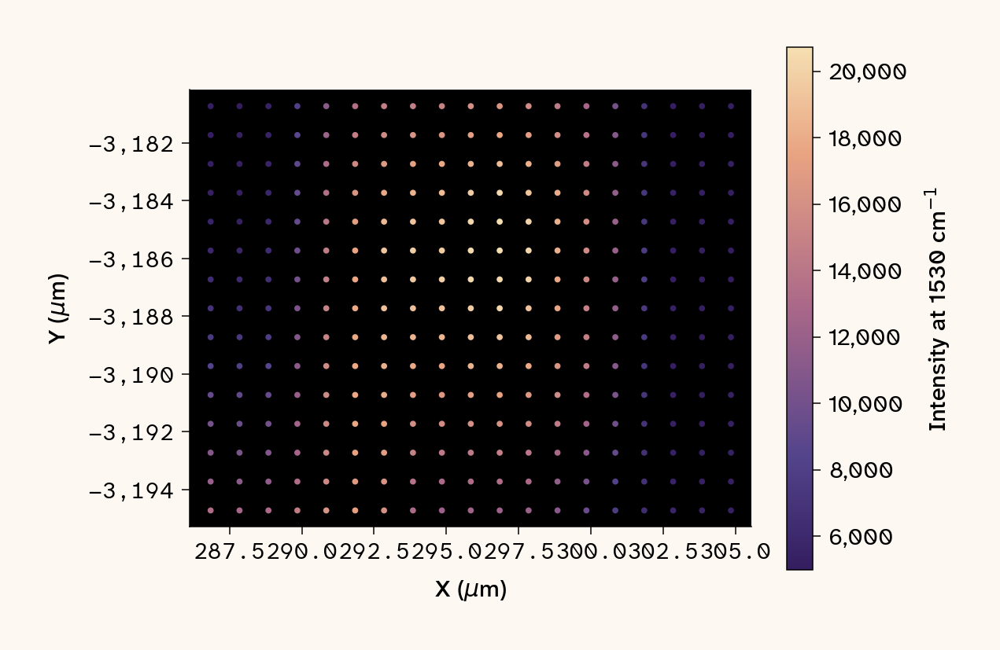

In [27]:
# | code-fold: true
# | code-summary: "Source code for this figure:"
# | label: fig-785spectralmap
# | fig-cap: "Spatial intensity map of *Chlamydomonas smithii* CC-1373 with 785 nm excitation, at the carotenoid ν₁ peak (~1530 cm⁻¹)."
# | fig-alt: "Static spatial intensity map of *Chlamydomonas smithii* CC-1373 at the carotenoid ν₁ peak (~1530 cm⁻¹), 785 nm excitation, black background, magma colorscale."

import os

# Renishaw 785 nm data is in long format (X, Y, Wave, Intensity), unlike Horiba wide format
df = pd.read_csv(
    red_path, sep="\t", usecols=[0, 1, 2, 3], names=["X", "Y", "Wave", "Intensity"], skiprows=1
)
xy_unique = df[["X", "Y"]].drop_duplicates().reset_index(drop=True)
red_num_points = len(xy_unique)
raman_shifts = sorted(df["Wave"].unique())

# Pivot long -> wide so downstream code matches the Horiba data
data_wide = df.pivot_table(index=["X", "Y"], columns="Wave", values="Intensity", aggfunc="first")
data_wide = data_wide.reset_index()
data = data_wide.rename(columns={"X": "x", "Y": "y"})

allowed_cols = [s for s in raman_shifts if 300 <= s <= 3600]

backup_path = "assets/785nm_interactive_spectralmap.html"
if not os.path.exists(backup_path):
    df_long = data.melt(
        id_vars=["x", "y"], value_vars=allowed_cols, var_name="raman_shift", value_name="intensity"
    )
    df_long["raman_shift"] = df_long["raman_shift"].astype(float)
    df_long["intensity"] = pd.to_numeric(df_long["intensity"], errors="coerce")
    df_long = df_long.sort_values(by="raman_shift")
    mean_spec = df_long.groupby("raman_shift", as_index=False)["intensity"].mean()
    unique_shifts = sorted(df_long["raman_shift"].unique())
    magma_colorscale = apc.gradients.magma.to_plotly_colorscale()

    fig_i = make_subplots(rows=2, cols=1, row_heights=[0.65, 0.35], vertical_spacing=0.15)
    init_shift = unique_shifts[0]
    fig_i.add_trace(
        go.Scatter(
            x=data["x"],
            y=data["y"],
            mode="markers",
            marker=dict(
                size=10,
                color=data[init_shift],
                colorscale=magma_colorscale,
                colorbar=dict(title=dict(text="Intensity")),
            ),
        ),
        row=1,
        col=1,
    )
    fig_i.add_trace(
        go.Scatter(
            x=mean_spec["raman_shift"],
            y=mean_spec["intensity"],
            mode="lines",
            line=dict(color="black"),
        ),
        row=2,
        col=1,
    )
    frames = []
    for shift in unique_shifts:
        frames.append(
            go.Frame(
                data=[
                    go.Scatter(
                        x=data["x"],
                        y=data["y"],
                        marker=dict(color=data[shift], colorscale=magma_colorscale),
                    ),
                    go.Scatter(x=mean_spec["raman_shift"], y=mean_spec["intensity"], mode="lines"),
                ],
                layout=dict(
                    shapes=[
                        dict(
                            type="line",
                            x0=shift,
                            x1=shift,
                            y0=mean_spec["intensity"].min(),
                            y1=mean_spec["intensity"].max(),
                            xref="x2",
                            yref="y2",
                            line=dict(color="black", width=2),
                            opacity=0.5,
                        )
                    ]
                ),
                name=str(shift),
            )
        )
    fig_i.frames = frames
    slider_steps = [
        dict(
            method="animate",
            args=[
                [str(s)],
                dict(
                    mode="immediate",
                    frame=dict(duration=100, redraw=True),
                    transition=dict(duration=0),
                ),
            ],
            label=str(round(s, 1)),
        )
        for s in unique_shifts
    ]
    fig_i.update_layout(
        sliders=[
            dict(
                active=0,
                currentvalue=dict(prefix="Raman shift (cm⁻¹): "),
                pad={"t": 10},
                steps=slider_steps,
                x=0,
                y=-0.1,
                len=1,
            )
        ],
        width=800,
        height=1200,
        showlegend=False,
        plot_bgcolor="black",
        paper_bgcolor="#FDF8F2",
        font=dict(family="Helvetica Neue", color="black"),
    )
    fig_i.write_html(backup_path, include_plotlyjs="cdn")

# Static spatial map at the 1530 cm⁻¹ carotenoid peak.
target_wn = 1530
idx_1530 = int(np.argmin(np.abs(np.array(allowed_cols) - target_wn)))
actual_wn = allowed_cols[idx_1530]
intensities = data[actual_wn]

fig, ax = plt.subplots(figsize=(8, 6), facecolor=apc.parchment)
sc = ax.scatter(data["x"], data["y"], c=intensities, cmap=apc.gradients.magma.to_mpl_cmap(), s=15)
plt.colorbar(sc, ax=ax, label=f"Intensity at {actual_wn:.0f} cm$^{{-1}}$")
ax.set_xlabel("X ($\\mu$m)")
ax.set_ylabel("Y ($\\mu$m)")
ax.set_aspect("equal")
ax.set_facecolor("black")
apc.mpl.style_plot(monospaced_axes="both")
plt.show()

Each map shows spatial heterogeneity across the cell(s), with hot spots especially evident in the 473 nm data. When the scrollbar is placed at a wavenumber where Raman peaks appear, some hot spots start to show clearer structure suggesting distinct cellular components.

### Data pre-processing

While the initial spectral plots and maps are already illuminating, two refinement steps improve the quality of downstream analysis. First, intensity-based spatial masking removes background points (map positions that didn't intersect a cell), so that subsequent analysis isn't diluted by off-cell signal. Second, baseline correction removes broad fluorescence contributions that ride underneath the Raman peaks, making peak positions and relative intensities more accurate and comparable across wavelengths.

#### Cell masking with intensity thresholding

To improve our analysis, we need to separate spatial points that are "on-cell" from background points. We'll use simple intensity thresholding based on mean intensity across the spectrum. This approach is interpretable and works well when cells have consistently higher signal than background. Thresholds were set at the 42nd, 30th, and 40th percentile of mean intensity for the 473 nm (@fig-intensity-masking-473), 532 nm (@fig-intensity-masking-532), and 785 nm datasets (@fig-intensity-masking-785), respectively, chosen by visual inspection of the resulting masks to retain clearly on-cell points while excluding background. The higher threshold for the 785 nm dataset reflects its stronger fluorescence background, which raises the mean intensity of background points relative to the other datasets.

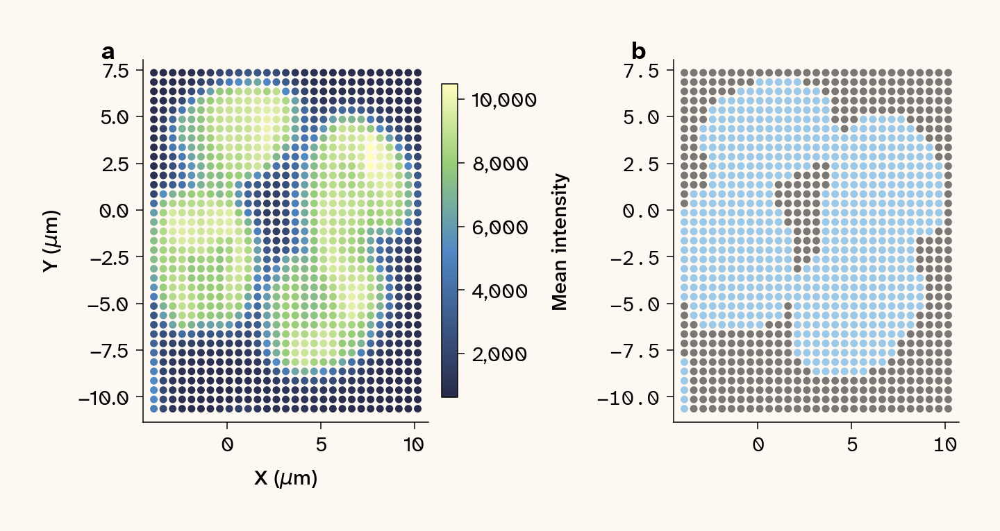

In [28]:
# | code-fold: true
# | code-summary: "Source code for this figure:"
# | label: fig-intensity-masking-473
# | fig-cap: "Intensity-based cell masking of the 473 nm dataset. (a) Spatial map of mean spectral intensity per pixel. (b) Binary mask after applying an intensity threshold (blue = retained on-cell points, gray = excluded background)."
# | fig-alt: "Two-panel figure for the 473 nm dataset. (a) Spatial scatter map of mean spectral intensity per pixel. (b) Binary mask retaining on-cell points (blue) and excluding background (gray) after applying an intensity threshold."

# Assign arcadia_pycolor colors
apc_473 = apc.aegean
apc_532 = apc.lime
apc_785 = apc.dragon

# Create diverging colormap for binary masks (off-cell to on-cell)
binary_cmap = ListedColormap([apc.slate, apc.vital])

# Calculate mean intensity for each spatial point
mean_intensity_473 = blue_intensity_filt.mean(axis=1)
mean_intensity_532 = green_intensity_filt.mean(axis=1)
mean_intensity_785 = red_intensity_filt.mean(axis=1)

# Calculate threshold (42nd percentile)
threshold_473 = np.percentile(mean_intensity_473, 42)
mask_473 = mean_intensity_473 > threshold_473

# Create 2-panel figure (1000px = 10 inches at 100 DPI)
fig, (ax_spatial, ax_mask) = plt.subplots(1, 2, figsize=(10, 5), facecolor=apc.parchment)

# a - Spatial intensity map
scatter = ax_spatial.scatter(
    blue_xy["x_pos"],
    blue_xy["y_pos"],
    c=mean_intensity_473,
    cmap=apc.gradients.viridis.to_mpl_cmap(),
    s=30,
)
ax_spatial.set_xlabel("X ($\\mu$m)")
ax_spatial.set_ylabel("Y ($\\mu$m)")
ax_spatial.set_aspect("equal")
cbar = plt.colorbar(scatter, ax=ax_spatial, fraction=0.046, pad=0.04)
cbar.set_label("Mean intensity")
ax_spatial.set_facecolor(apc.parchment)
ax_spatial.text(
    -0.15, 1.05, "a", transform=ax_spatial.transAxes, fontsize=18, fontweight="bold", va="top"
)
apc.mpl.style_plot(monospaced_axes="both")

# b - Binary mask
ax_mask.scatter(blue_xy["x_pos"], blue_xy["y_pos"], c=mask_473, cmap=binary_cmap, s=30, alpha=0.7)
ax_mask.set_aspect("equal")
ax_mask.set_facecolor(apc.parchment)
ax_mask.text(
    -0.15, 1.05, "b", transform=ax_mask.transAxes, fontsize=18, fontweight="bold", va="top"
)
apc.mpl.style_plot(monospaced_axes="both")

plt.tight_layout()
plt.savefig("assets/fig-masking-473nm.pdf", bbox_inches="tight", dpi=300)
plt.show()

# Create masked datasets for downstream analysis
blue_intensity_masked = blue_intensity_filt[mask_473]
blue_xy_masked = blue_xy[mask_473].reset_index(drop=True)
cell_473 = blue_intensity_masked.values
mean_473 = pd.Series(cell_473.mean(axis=0), index=blue_intensity_filt.columns)

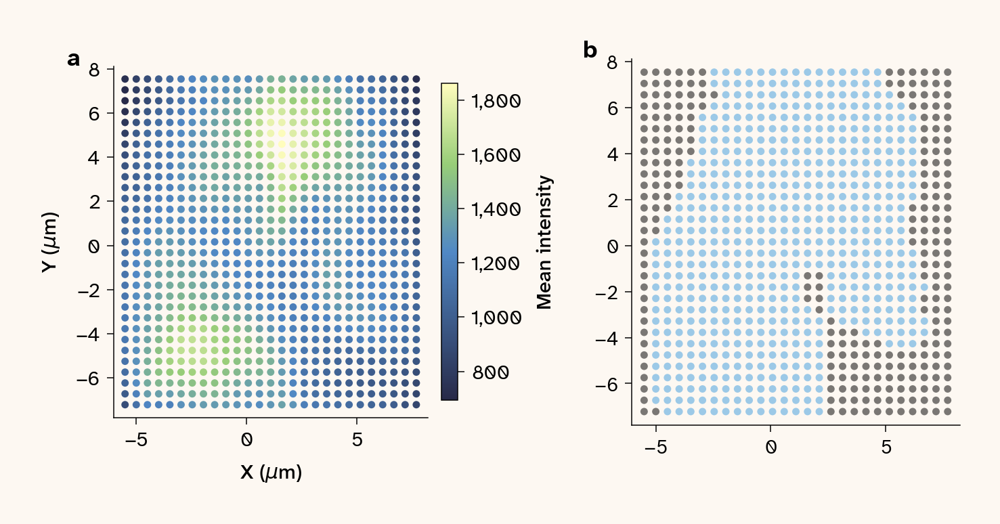

In [29]:
# | code-fold: true
# | code-summary: "Source code for this figure:"
# | label: fig-intensity-masking-532
# | fig-cap: "Intensity-based cell masking of the 532 nm dataset. (a) Spatial map of mean spectral intensity per pixel. (b) Binary mask after applying an intensity threshold (blue = retained on-cell points, gray = excluded background)."
# | fig-alt: "Two-panel figure for the 532 nm dataset. (a) Spatial scatter map of mean spectral intensity per pixel. (b) Binary mask retaining on-cell points (blue) and excluding background (gray) after applying an intensity threshold."

# Calculate threshold (30th percentile)
threshold_532 = np.percentile(mean_intensity_532, 30)
mask_532 = mean_intensity_532 > threshold_532

# Create 2-panel figure (1000px = 10 inches at 100 DPI)
fig, (ax_spatial, ax_mask) = plt.subplots(1, 2, figsize=(10, 5), facecolor=apc.parchment)

# a - Spatial intensity map
scatter = ax_spatial.scatter(
    green_xy["x_pos"],
    green_xy["y_pos"],
    c=mean_intensity_532,
    cmap=apc.gradients.viridis.to_mpl_cmap(),
    s=30,
)
ax_spatial.set_xlabel("X ($\\mu$m)")
ax_spatial.set_ylabel("Y ($\\mu$m)")
ax_spatial.set_aspect("equal")
cbar = plt.colorbar(scatter, ax=ax_spatial, fraction=0.046, pad=0.04)
cbar.set_label("Mean intensity")
ax_spatial.set_facecolor(apc.parchment)
ax_spatial.text(
    -0.15, 1.05, "a", transform=ax_spatial.transAxes, fontsize=18, fontweight="bold", va="top"
)
apc.mpl.style_plot(monospaced_axes="both")

# b - Binary mask
ax_mask.scatter(green_xy["x_pos"], green_xy["y_pos"], c=mask_532, cmap=binary_cmap, s=30, alpha=0.7)
ax_mask.set_aspect("equal")
ax_mask.set_facecolor(apc.parchment)
ax_mask.text(
    -0.15, 1.05, "b", transform=ax_mask.transAxes, fontsize=18, fontweight="bold", va="top"
)
apc.mpl.style_plot(monospaced_axes="both")

plt.tight_layout()
plt.savefig("assets/fig-masking-532nm.pdf", bbox_inches="tight", dpi=300)
plt.show()

# Create masked datasets for downstream analysis
green_intensity_masked = green_intensity_filt[mask_532]
green_xy_masked = green_xy[mask_532].reset_index(drop=True)
cell_532 = green_intensity_masked.values
mean_532 = pd.Series(cell_532.mean(axis=0), index=green_intensity_filt.columns)

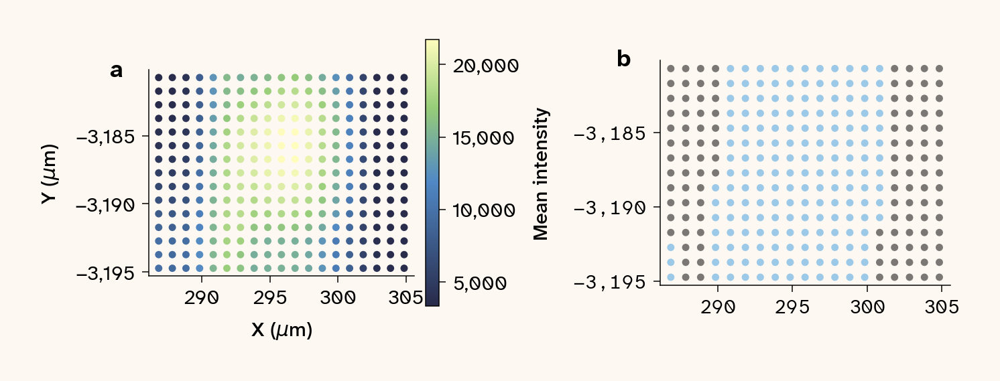

In [30]:
# | code-fold: true
# | code-summary: "Source code for this figure:"
# | label: fig-intensity-masking-785
# | fig-cap: "Intensity-based cell masking of the 785 nm dataset. (a) Spatial map of mean spectral intensity per pixel. (b) Binary mask after applying an intensity threshold (blue = retained on-cell points, gray = excluded background)."
# | fig-alt: "Two-panel figure for the 785 nm dataset. (a) Spatial scatter map of mean spectral intensity per pixel. (b) Binary mask retaining on-cell points (blue) and excluding background (gray) after applying an intensity threshold."

# Calculate threshold (40th percentile)
threshold_785 = np.percentile(mean_intensity_785, 40)
mask_785 = mean_intensity_785 > threshold_785

# Create 2-panel figure (1000px = 10 inches at 100 DPI)
fig, (ax_spatial, ax_mask) = plt.subplots(1, 2, figsize=(10, 5), facecolor=apc.parchment)

# a - Spatial intensity map
scatter = ax_spatial.scatter(
    red_xy["X"],
    red_xy["Y"],
    c=mean_intensity_785,
    cmap=apc.gradients.viridis.to_mpl_cmap(),
    s=30,
)
ax_spatial.set_xlabel("X ($\\mu$m)")
ax_spatial.set_ylabel("Y ($\\mu$m)")
ax_spatial.set_aspect("equal")
cbar = plt.colorbar(scatter, ax=ax_spatial, fraction=0.046, pad=0.04)
cbar.set_label("Mean intensity")
ax_spatial.set_facecolor(apc.parchment)
ax_spatial.text(
    -0.15, 1.05, "a", transform=ax_spatial.transAxes, fontsize=18, fontweight="bold", va="top"
)
apc.mpl.style_plot(monospaced_axes="both")

# b - Binary mask
ax_mask.scatter(red_xy["X"], red_xy["Y"], c=mask_785, cmap=binary_cmap, s=30, alpha=0.7)
ax_mask.set_aspect("equal")
ax_mask.set_facecolor(apc.parchment)
ax_mask.text(
    -0.15, 1.05, "b", transform=ax_mask.transAxes, fontsize=18, fontweight="bold", va="top"
)
apc.mpl.style_plot(monospaced_axes="both")

plt.tight_layout()
plt.savefig("assets/fig-masking-785nm.pdf", bbox_inches="tight", dpi=300)
plt.show()

# Create masked datasets for downstream analysis
red_intensity_masked = red_intensity_filt[mask_785]
red_xy_masked = red_xy[mask_785].reset_index(drop=True)
cell_785 = red_intensity_masked.values
mean_785 = pd.Series(cell_785.mean(axis=0), index=red_intensity_filt.columns)

#### Baseline correction and peak finding

Now that we have masked data containing only "on-cell" points, let's apply baseline correction to remove fluorescence backgrounds and identify peaks. We'll use the 'airPLS' algorithm from 'pybaselines', which is effective at removing broad baseline features while preserving sharp spectral peaks. We use `lam=1e6` for airPLS across all three datasets — a moderately stiff smoothness parameter that subtracts broad fluorescence while leaving sharp Raman peaks intact. A single value was used across datasets for comparability. For the 785 nm data, we first subtract the off-cell background since glass fluorescence dominates the baseline (@fig-785-background-subtraction), then apply airPLS to all three datasets (@fig-473-baselined, @fig-532-baselined, @fig-785-baselined). The three baseline-corrected mean spectra are overlaid for direct comparison (@fig-baselined-overlay). The examples below all use the mean spectra. 

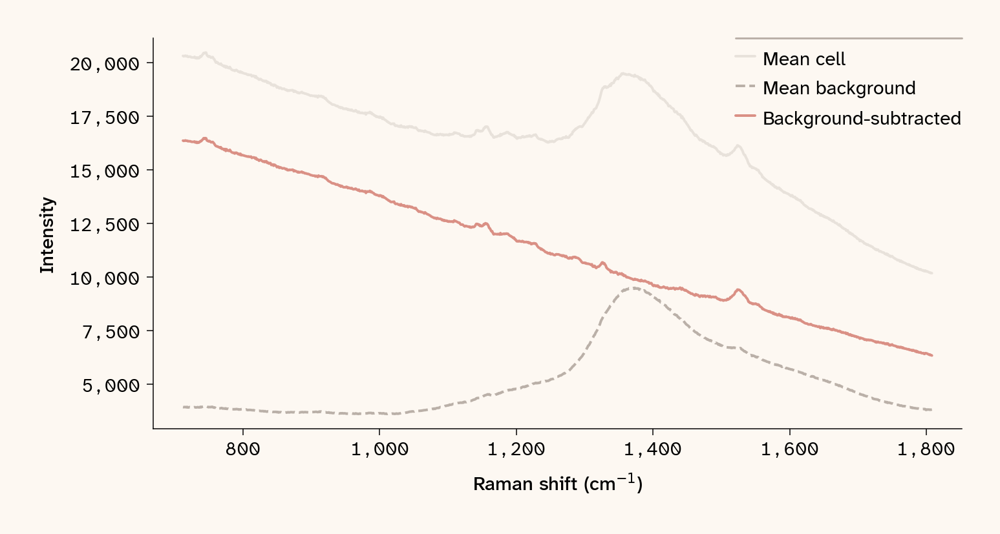

In [31]:
# | code-fold: true
# | code-summary: "Source code for this figure:"
# | label: fig-785-background-subtraction
# | fig-cap: "Background subtraction prior to baseline correction for the 785 nm dataset. The mean off-cell background spectrum (largely glass and TAP medium fluorescence) is subtracted from each on-cell spectrum before airPLS baseline correction is applied."
# | fig-alt: "Line plot showing 785 nm mean on-cell spectrum, the off-cell background spectrum, and the result of subtracting the background from the on-cell signal before baseline correction."

# Baseline correction for all three wavelengths

# Define wavenumber arrays from mean spectrum indices (needed for downstream analysis)
wavenumbers_473 = mean_473.index.values
wavenumbers_532 = mean_532.index.values
wavenumbers_785 = mean_785.index.values

# 473nm and 532nm: airPLS
baseline_result_473 = airpls(mean_473.values, lam=1e6)
baseline_473 = (
    baseline_result_473[0] if isinstance(baseline_result_473, tuple) else baseline_result_473
)
corrected_473 = mean_473.values - baseline_473

baseline_result_532 = airpls(mean_532.values, lam=1e6)
baseline_532 = (
    baseline_result_532[0] if isinstance(baseline_result_532, tuple) else baseline_result_532
)
corrected_532 = mean_532.values - baseline_532

# ========== 785nm BASELINE CORRECTION WITH BACKGROUND SUBTRACTION ==========

# Identify background (off-cell) points using the mask
background_points_785 = red_intensity_filt[~mask_785]

# Calculate mean background spectrum from off-cell points
mean_background_785 = background_points_785.mean(axis=0)

# Subtract background from all cell spectra BEFORE baseline correction
# This removes the bulk glass fluorescence
cell_785_bkgd_subtracted = cell_785 - mean_background_785.values

# Recalculate mean spectrum after background subtraction
mean_785_bkgd_subtracted = cell_785_bkgd_subtracted.mean(axis=0)

# Apply airPLS baseline correction to the background-subtracted data
baseline_result_785 = airpls(mean_785_bkgd_subtracted, lam=1e6)
baseline_785 = (
    baseline_result_785[0] if isinstance(baseline_result_785, tuple) else baseline_result_785
)
corrected_785 = mean_785_bkgd_subtracted - baseline_785

# Create figure showing the process
fig, axes = plt.subplots(
    figsize=(10, 5), layout="constrained", nrows=1, ncols=1, facecolor=apc.parchment
)

# Plot background spectrum and subtraction
axes.plot(
    wavenumbers_785, mean_785.values, color=apc.chateau, alpha=0.3, linewidth=2, label="Mean cell"
)
axes.plot(
    mean_background_785.index.values,
    mean_background_785.values,
    color=apc.chateau,
    linestyle="--",
    linewidth=2,
    label="Mean background",
)
axes.plot(
    wavenumbers_785,
    mean_785_bkgd_subtracted,
    color=apc.mars,
    linewidth=2,
    label="Background-subtracted",
)
axes.set_xlabel("Raman shift (cm$^{-1}$)")
axes.set_ylabel("Intensity")
axes.legend(loc="upper right")
axes.grid(False)

apc.mpl.style_plot(monospaced_axes="both")
plt.savefig("assets/fig-785-background-subtraction.pdf", dpi=300, bbox_inches="tight")
plt.show()

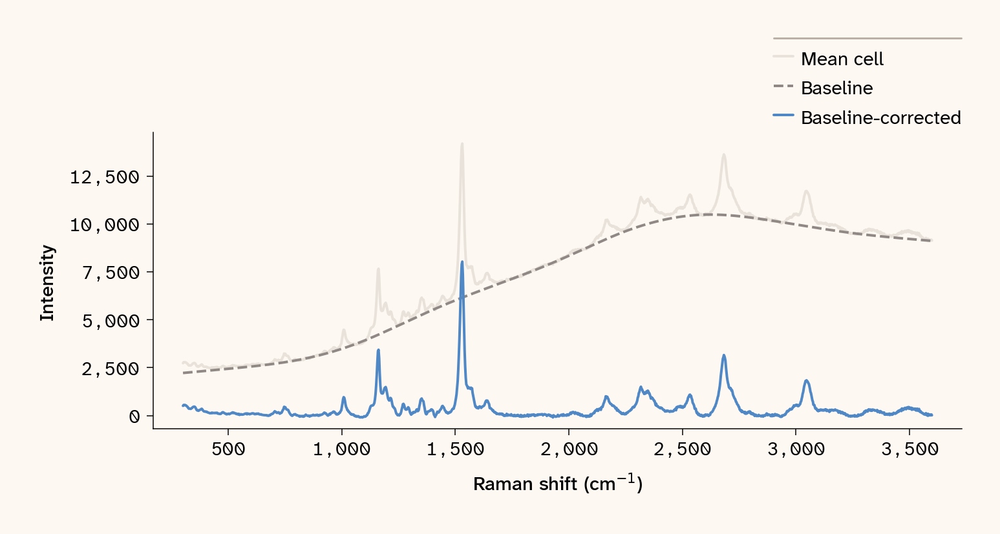

In [32]:
# | code-fold: true
# | code-summary: "Source code for this figure:"
# | label: fig-473-baselined
# | fig-cap: "Mean 473 nm on-cell spectrum (gray), airPLS-fitted baseline (dashed), and the resulting baseline-corrected spectrum (blue)."
# | fig-alt: "Mean 473 nm on-cell spectrum (gray), airPLS-fitted baseline (dashed), and the resulting baseline-corrected spectrum (blue)."

# 473nm baseline correction figure
fig, ax = plt.subplots(
    figsize=(10, 5), layout="constrained", nrows=1, ncols=1, facecolor=apc.parchment
)

ax.plot(
    mean_473.index.values,
    mean_473.values,
    color=apc.chateau,
    alpha=0.3,
    linewidth=2,
    label="Mean cell",
)
ax.plot(
    mean_473.index.values,
    baseline_473,
    color=apc.bark,
    linestyle="--",
    label="Baseline",
    linewidth=2,
)
ax.plot(
    mean_473.index.values, corrected_473, color=apc_473, label="Baseline-corrected", linewidth=2
)
ax.set_xlabel("Raman shift (cm$^{-1}$)")
ax.set_ylabel("Intensity")
ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.02))
ax.set_facecolor(apc.parchment)

apc.mpl.style_plot(monospaced_axes="both")
plt.savefig("assets/fig-baseline-473nm.pdf", dpi=300, bbox_inches="tight")
plt.show()

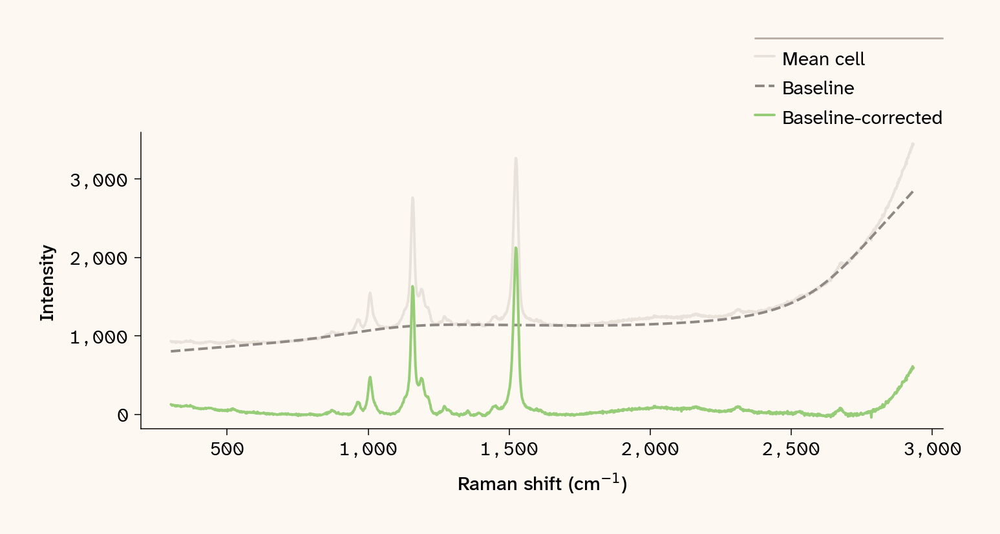

In [33]:
# | code-fold: true
# | code-summary: "Source code for this figure:"
# | label: fig-532-baselined
# | fig-cap: "Mean 532 nm on-cell spectrum (gray), airPLS-fitted baseline (dashed), and the resulting baseline-corrected spectrum (green)."
# | fig-alt: "Mean 532 nm on-cell spectrum (gray), airPLS-fitted baseline (dashed), and the resulting baseline-corrected spectrum (green)."

# 532nm baseline correction figure
fig, ax = plt.subplots(
    figsize=(10, 5), layout="constrained", nrows=1, ncols=1, facecolor=apc.parchment
)

ax.plot(
    mean_532.index.values,
    mean_532.values,
    color=apc.chateau,
    alpha=0.3,
    linewidth=2,
    label="Mean cell",
)
ax.plot(
    mean_532.index.values,
    baseline_532,
    color=apc.bark,
    linestyle="--",
    label="Baseline",
    linewidth=2,
)
ax.plot(
    mean_532.index.values, corrected_532, color=apc_532, label="Baseline-corrected", linewidth=2
)
ax.set_xlabel("Raman shift (cm$^{-1}$)")
ax.set_ylabel("Intensity")
ax.legend(
    loc="lower right",
    bbox_to_anchor=(1.0, 1.02),
    frameon=True,
    facecolor=apc.parchment,
    edgecolor="gray",
    framealpha=1,
)
ax.set_facecolor(apc.parchment)

apc.mpl.style_plot(monospaced_axes="both")
plt.savefig("assets/fig-baseline-532nm.pdf", dpi=300, bbox_inches="tight")
plt.show()

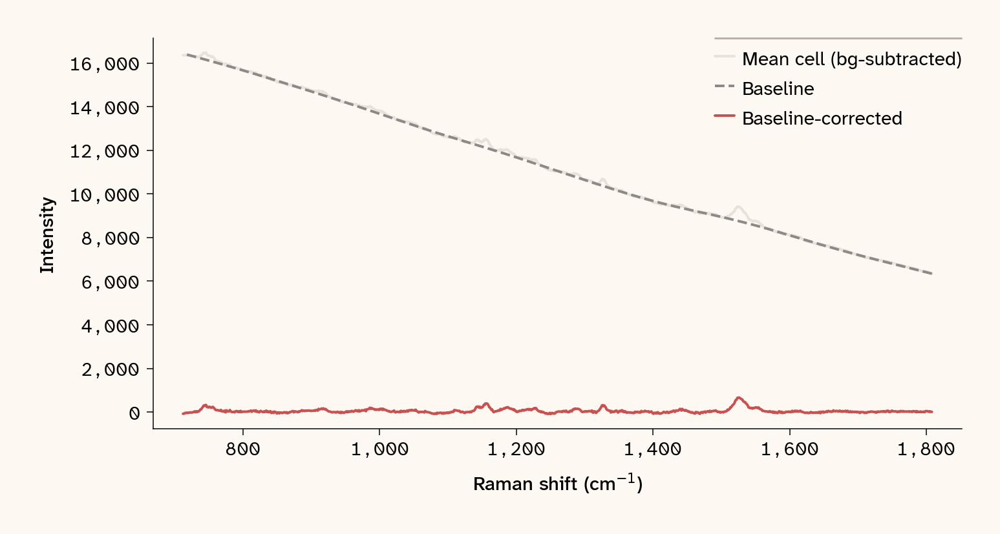

In [34]:
# | code-fold: true
# | code-summary: "Source code for this figure:"
# | label: fig-785-baselined
# | fig-cap: "Mean 785 nm on-cell spectrum after background subtraction (gray), airPLS-fitted baseline (dashed), and the resulting baseline-corrected spectrum (red)."
# | fig-alt: "Mean 785 nm on-cell spectrum after background subtraction (gray), airPLS-fitted baseline (dashed), and the resulting baseline-corrected spectrum (red)."

# 785nm baseline correction figure
fig, ax1 = plt.subplots(
    figsize=(10, 5), layout="constrained", nrows=1, ncols=1, facecolor=apc.parchment
)

ax1.plot(
    wavenumbers_785,
    mean_785_bkgd_subtracted,
    color=apc.chateau,
    alpha=0.3,
    linewidth=2,
    label="Mean cell (bg-subtracted)",
)
ax1.plot(
    mean_785.index.values,
    baseline_785,
    color=apc.bark,
    linestyle="--",
    label="Baseline",
    linewidth=2,
)
ax1.plot(
    mean_785.index.values, corrected_785, color=apc_785, label="Baseline-corrected", linewidth=2
)
ax1.set_xlabel("Raman shift (cm$^{-1}$)")
ax1.set_ylabel("Intensity")
ax1.legend(loc="upper right")
ax1.set_facecolor(apc.parchment)

apc.mpl.style_plot(monospaced_axes="both")
plt.savefig("assets/fig-baseline-785nm.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [35]:
# | code-fold: true
# | code-summary: "Source code for this figure:"
# | label: fig-baselined-overlay
# | fig-cap: "Interactive overlay of baseline-corrected mean spectra from all three wavelengths on a common axis. Vertical dotted lines mark the peaks discussed in the text (Car = carotenoid, Chl = chlorophyll). Use the Plotly toolbar or click-and-drag to zoom into specific wavenumber ranges or peaks of interest."
# | fig-alt: "Interactive overlay of the baseline-corrected mean spectra at all three excitation wavelengths on a common axis, with vertical dotted lines marking peaks attributed to carotenoid, chlorophyll, and lipid in the body text."

# Create Plotly figure with raw intensity comparison
fig = go.Figure()

# Add traces for each wavelength
fig.add_trace(
    go.Scatter(
        x=wavenumbers_473,
        y=corrected_473,
        mode="lines",
        name="473 nm",
        line=dict(color=apc_473, width=2),
        opacity=0.8,
    )
)

fig.add_trace(
    go.Scatter(
        x=wavenumbers_532,
        y=corrected_532,
        mode="lines",
        name="532 nm",
        line=dict(color=apc_532, width=2),
        opacity=0.8,
    )
)

fig.add_trace(
    go.Scatter(
        x=wavenumbers_785,
        y=corrected_785,
        mode="lines",
        name="785 nm",
        line=dict(color=apc_785, width=2),
        opacity=0.8,
    )
)


# Annotate named peaks discussed in the body text. Vertical lines + labels at
# the top mark each peak; assignment (Car/Chl/Lipid) is shown above the line.
named_peaks = [
    (746, "Chl"),
    (1005, "Car"),
    (1157, "Car"),
    (1189, "Chl"),
    (1289, "Chl"),
    (1444, "Lip"),
    (1530, "Car"),
    (2650, "Car"),
]
peak_shapes = [
    dict(
        type="line",
        x0=wn,
        x1=wn,
        y0=0,
        y1=1.02 if i % 2 == 0 else 1.15,
        xref="x",
        yref="paper",
        line=dict(color="gray", width=1, dash="dot"),
    )
    for i, (wn, _) in enumerate(named_peaks)
]
peak_annotations = [
    dict(
        x=wn,
        y=1.05 if i % 2 == 0 else 1.18,
        xref="x",
        yref="paper",
        text=label,
        showarrow=False,
        font=dict(size=14, color="gray"),
        xanchor="center",
    )
    for i, (wn, label) in enumerate(named_peaks)
]

# Update layout
fig.update_layout(
    shapes=peak_shapes,
    annotations=peak_annotations,
    width=800,
    height=450,
    margin=dict(t=70),
    xaxis_title="Raman shift (cm⁻¹)",
    yaxis_title="Intensity (baseline-corrected)",
    xaxis=dict(range=[300, 3600], showgrid=False),
    yaxis=dict(showgrid=False),
    plot_bgcolor=apc.parchment,
    paper_bgcolor=apc.parchment,
    legend=dict(x=1.0, y=0.95, xanchor="right", yanchor="top"),
)

apc.plotly.style_plot(fig, monospaced_axes="all")

fig.show()

After baseline correction, the broad fluorescence contribution is substantially reduced across all three datasets and the fingerprint region (400–1800 cm⁻¹) becomes more interpretable. The chemistry visible at each wavelength differs.

The 473 nm dataset shows by far the most peaks, with many peaks visible well above the noise floor. The carotenoid ν₂ (~1162 cm⁻¹), ν₁ (~1530 cm⁻¹), and ν₃ (~1005 cm⁻¹) modes [@vasimov2026carotenoids] are sharp and well-resolved. Chlorophyll-attributable peaks appear at ~746, ~1189, and ~1289 cm⁻¹ [@pandey2022microraman], and the ~1444 cm⁻¹ peak is likely lipid CH₂ scissoring [@samek2010algal].

The 532 nm dataset shows a fair number of high-intensity peaks, mostly from carotenoids. A few peaks attributable to chlorophyll are detectable (e.g., ~1189 cm⁻¹) along with the likely lipid peak at ~1444 cm⁻¹, but the 746 and 1289 cm⁻¹ chlorophyll peaks are not clearly resolved — likely because chlorophyll absorbs near 532 nm at the Q-band tail and the resulting baseline fluorescence obscures the weaker chlorophyll Raman peaks.

The 785 nm dataset has the weakest signal overall, as it is off-resonance for all pigments. The major carotenoid peaks (~1157, ~1530 cm⁻¹), chlorophyll peaks (~746, ~1189, ~1289 cm⁻¹), and the likely lipid peak at ~1444 cm⁻¹ are all visible, but minor carotenoid features such as the ν₃ mode resolved at 473 nm are not clearly detectable here. 

### Spatial heterogeneity analysis

All three datasets are compared in the univariate marker maps below; for PCA and NMF we focus exclusively on the 473 nm dataset, which has the highest point density and SNR of the three (see justification after the marker maps). In all datasets, it's possible to distinguish the cells from the background to varying degrees. However, we're interested in whether we can distinguish cellular substructures or organelles, such as the eyespot or chloroplasts. There are a few ways we can start to pull apart the data to find natural clusters or decompose the spectra themselves. Not all methods are equally useful for all datasets, so it's worth considering what to try at the outset.

At the most basic level, we could do simple univariate analysis by creating maps that show intensity at a single wavenumber for each xy point. We could select known Raman peak positions as markers for specific biomolecules relevant to our system; for instance, ~1530 cm⁻¹ for the C=C symmetrical stretch of carotenoids, which we know are present in *Chlamydomonas*. In each map, hot spots of high intensity at this wavenumber would be expected to correlate with the positions of organelles or components rich in the biomolecule of interest. For carotenoids, this could be the eyespot. This is something we can already do to an extent with the interactive spectral maps above, but applying it to baseline-corrected, masked data is more useful. This method is simple and biologically grounded, but requires prior knowledge of what to look for and the wavenumber of interest, can't resolve overlapping markers, and may not be well-suited for multi-molecular organelles. 

Next, we could try various forms of unsupervised decomposition to find spectrally distinct components. Principal Component Analysis (PCA) finds directions of maximum spectral variance, useful for quick compartmentalization into different composition groups (e.g., eyespot vs. non-eyespot) and general exploration of the dataset. However, it can't always separate mixed components, might miss subtle differences, and can be difficult to interpret since components can be negative. It is often used as a first-pass analysis for spectral data. Non-negative matrix factorization (NMF), by contrast, decomposes the data into non-negative spectral components that are more likely to be interpretable, estimates spectral unmixing, and can be effective for biochemical compartmentalization. However, it requires selecting the number of components and at least moderate SNR. Other approaches, including hierarchical clustering, k-means, and UMAP, are potentially applicable to this type of data but weren't pursued here. Our dataset is small and lacks sufficient point density per cell for clustering to be reliable, and UMAP would require pairing with a decomposition method to be interpretable.

#### Single-wavenumber marker maps

Let's select three different molecules of interest: carotenoids, chlorophylls, and lipids. All of these should be abundant in the cells and have Raman-detectable vibrational modes. We can use the C=C stretching mode at ~1530 cm⁻¹ as a marker for carotenoids [@kubo2000eyespot], the mode at ~746 cm⁻¹ for chlorophylls [@jehlicka2014pigments], and the CH₂ scissoring mode at ~1444 cm⁻¹ for lipids [@samek2010algal; @pandey2024lipid]. Also, we can include 1780 cm⁻¹ as a control, because this is part of the silent region and present in all three datasets' ranges; no real peaks should be present here. These wavenumbers can also be changed in the code cell below.

These aren't the only peaks associated with any of these molecules, nor are these molecules the only ones that can have peaks at those wavenumbers. However, given what we know of the biology of these cells and prior work, they are reasonable Raman markers to use to generate univariate maps.

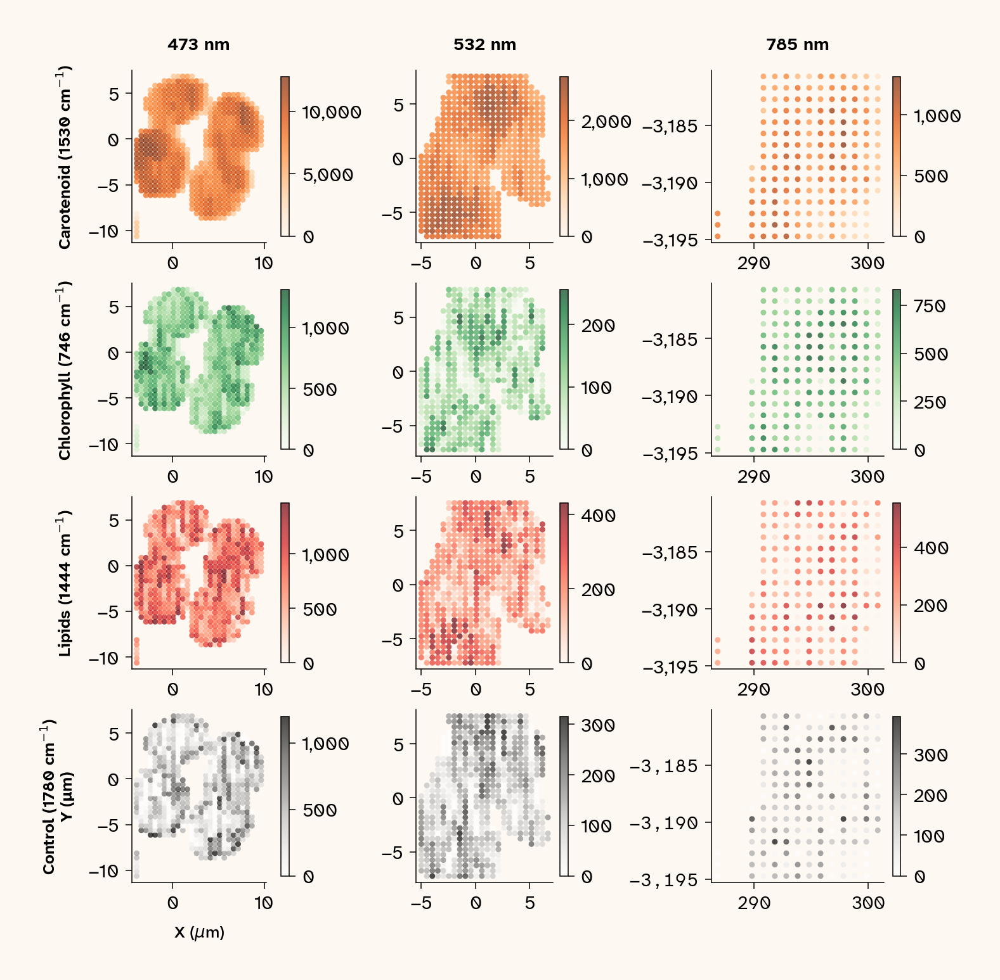

In [36]:
# | code-fold: true
# | code-summary: "Source code for this figure:"
# | label: fig-marker-spatial-maps
# | fig-cap: "Spatial distribution of biomolecular markers across the three datasets. Rows correspond to the four markers (Carotenoid 1530 cm⁻¹, Chlorophyll 746 cm⁻¹, Lipids 1444 cm⁻¹, Control 1780 cm⁻¹); columns to the three excitation wavelengths. Color intensity represents the baseline-corrected Raman intensity at each target wavenumber. Empty cells indicate the marker wavenumber is out of range for that dataset."
# | fig-alt: "Grid of spatial intensity maps. Rows: marker wavenumbers for Carotenoid (1530 cm⁻¹), Chlorophyll (746 cm⁻¹), Lipids (1444 cm⁻¹), and a Control (1780 cm⁻¹). Columns: 473, 532, and 785 nm excitation. Empty cells indicate the marker wavenumber is out of range for that dataset."

coords_for_markers = {
    "473nm": blue_xy[mask_473].reset_index(drop=True),
    "532nm": green_xy[mask_532].reset_index(drop=True),
    "785nm": red_xy[mask_785].reset_index(drop=True),
}

# Define target wavenumbers for each marker
markers = {
    "Carotenoid": 1530,
    "Chlorophyll": 746,
    "Lipids": 1444,
    "Control": 1780,
}


# Function to apply baseline correction and extract marker intensity
def extract_marker_intensity(spectra_array, wavenumbers, target_wn, lam=1e6):
    # Find closest wavenumber index
    idx = np.argmin(np.abs(wavenumbers - target_wn))

    # Apply baseline correction to each spectrum
    marker_intensities = np.zeros(len(spectra_array))
    for i, spectrum in enumerate(spectra_array.values):
        baseline_i = airpls(spectrum, lam=lam)
        baseline_i = baseline_i[0] if isinstance(baseline_i, tuple) else baseline_i
        corrected_spectrum = spectrum - baseline_i
        marker_intensities[i] = corrected_spectrum[idx]

    return marker_intensities


# Extract marker intensities for all wavelengths
marker_data = {}

for marker_name, target_wn in markers.items():
    marker_data[marker_name] = {}

    # 473 nm
    if target_wn >= wavenumbers_473.min() and target_wn <= wavenumbers_473.max():
        marker_data[marker_name]["473nm"] = extract_marker_intensity(
            blue_intensity_masked, wavenumbers_473, target_wn
        )
    else:
        marker_data[marker_name]["473nm"] = None

    # 532 nm
    if target_wn >= wavenumbers_532.min() and target_wn <= wavenumbers_532.max():
        marker_data[marker_name]["532nm"] = extract_marker_intensity(
            green_intensity_masked, wavenumbers_532, target_wn
        )
    else:
        marker_data[marker_name]["532nm"] = None

    # 785 nm (requires background subtraction first)
    if target_wn >= wavenumbers_785.min() and target_wn <= wavenumbers_785.max():
        # Subtract background before baseline correction
        red_intensity_bkgd_sub = red_intensity_masked.values - mean_background_785.values
        marker_data[marker_name]["785nm"] = extract_marker_intensity(
            pd.DataFrame(red_intensity_bkgd_sub, columns=red_intensity_masked.columns),
            wavenumbers_785,
            target_wn,
        )
    else:
        marker_data[marker_name]["785nm"] = None

marker_cmaps = {
    "Carotenoid": "Oranges",
    "Chlorophyll": "Greens",
    "Lipids": "Reds",
    "Control": "Greys",
}

# Create figure
fig = plt.figure(figsize=(10, 10), layout="constrained", facecolor=apc.parchment)
gs = fig.add_gridspec(4, 3, hspace=0.05, wspace=0.05)

# Use the coordinate arrays from Step 1 that match the intensity data
coords = coords_for_markers

wavelength_labels = ["473 nm", "532 nm", "785 nm"]
marker_names = ["Carotenoid", "Chlorophyll", "Lipids", "Control"]

for row_idx, marker_name in enumerate(marker_names):
    for col_idx, wavelength in enumerate(["473nm", "532nm", "785nm"]):
        ax = fig.add_subplot(gs[row_idx, col_idx])

        # Get marker intensity data
        intensities = marker_data[marker_name][wavelength]

        if intensities is not None:
            # Get coordinates
            xy = coords[wavelength]
            x_col = "x_pos" if wavelength != "785nm" else "X"
            y_col = "y_pos" if wavelength != "785nm" else "Y"

            # Ensure arrays have same length
            n_points = min(len(xy), len(intensities))
            if len(xy) != len(intensities):
                xy = xy.iloc[:n_points]
                intensities = intensities[:n_points]

            # Create scatter plot
            scatter = ax.scatter(
                xy[x_col],
                xy[y_col],
                c=intensities,
                cmap=marker_cmaps[marker_name],
                s=20,
                alpha=0.7,
                vmin=0,  # Ensure 0 baseline
                vmax=np.percentile(intensities, 99),  # Clip extreme values
            )

            # Colorbar
            cbar = plt.colorbar(scatter, ax=ax, fraction=0.046, pad=0.04)

        else:
            ax.set_visible(False)
            continue

        # Styling
        ax.set_aspect("equal")
        ax.set_facecolor(apc.parchment)

        # Labels
        if row_idx == 0:
            ax.set_title(wavelength_labels[col_idx], fontweight="bold", fontsize=14)
        if col_idx == 0:
            label = f"{marker_name} ({markers[marker_name]} cm$^{{-1}}$)"
            if row_idx == len(marker_names) - 1:
                label = f"{label}\nY (μm)"
            ax.set_ylabel(label, fontsize=13, fontweight="bold")
        else:
            ax.set_ylabel("", fontsize=9)

        if row_idx == len(marker_names) - 1 and col_idx == 0:
            ax.set_xlabel("X ($\\mu$m)", fontsize=13)


apc.mpl.style_plot(monospaced_axes="both")
plt.show()

The univariate maps (@fig-marker-spatial-maps) highlight several things. First, the 473 nm dataset is the only one with sufficient point density and SNR to be useful for further spatial heterogeneity analysis. The differently focused 532 nm dataset and the sparse map on a single cell for the 785 nm dataset make them difficult to glean meaning from. Second, there is some discernible structure in at least three maps, specifically the 473 nm and 532 nm carotenoid maps and the 473 nm chlorophyll map. The 473 and 532 nm lipid maps might show some structure, as well, but less clearly. 

#### Principal Component Analysis (PCA)

Continuing with the 473 nm dataset only, we can apply PCA, a quick way of assessing variance within the dataset, which separates the independent drivers of variance in the system into different dimensions. Because each point is a full spectrum with features that may co-vary, it can be useful to look at these patterns of variance. The components can also be mapped back onto the xy coordinates to assess localized patterns and possible compositional heterogeneity, such as from organelles (@fig-473-pca-maps). We apply PCA to the unmasked, lightly filtered data (retaining background points) because the contrast between cell and non-cell signal is itself informative and heavy pre-processing isn't needed for an initial exploratory analysis.

The diverging color scale on each spatial map shows the sign and magnitude of that component's loading at every pixel: one color marks positive loadings, the other marks negative loadings, and white marks near-zero loading. For PCA, the sign of any component is arbitrary (multiplying by −1 gives the same decomposition), so what's meaningful is the spatial pattern — which regions co-vary together — not the polarity.

  PC1: 99.2%
  PC2: 0.2%
  PC3: 0.1%
  PC4: 0.0%
  PC5: 0.0%
  PC6: 0.0%
  PC7: 0.0%
  PC8: 0.0%
  PC9: 0.0%
  PC10: 0.0%
  Total (PC1-10): 99.5%


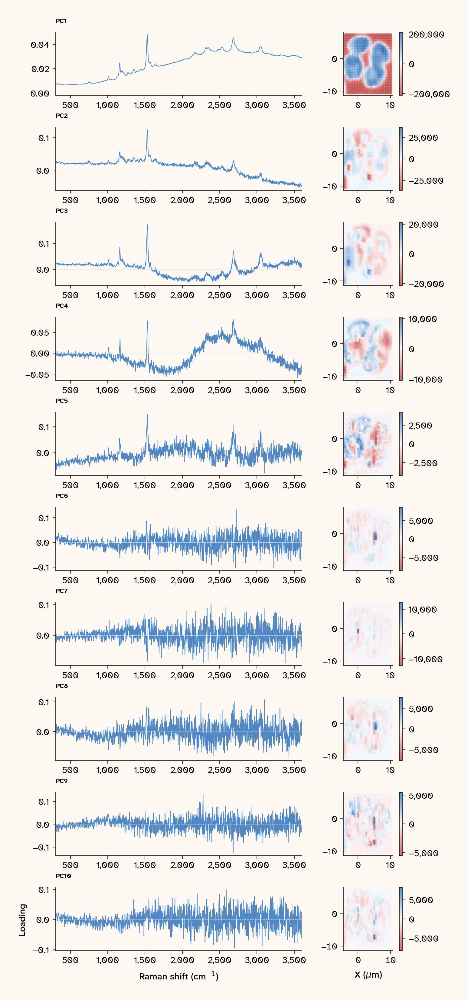

In [37]:
# | code-fold: true
# | code-summary: "Source code for this figure:"
# | label: fig-473-pca-maps
# | fig-cap: "PCA on the unmasked 473 nm dataset. Left column: PC loadings (spectral patterns) for components 1–10. Right column: per-pixel spatial scores using a symmetric red-blue colorscale. The loading (left, y-axis) is the spectral pattern of each component while the score (right, colorbar) is the per-pixel projection onto that pattern; they are different quantities and do not share a scale. Rows progress from PC1 (top) to PC10 (bottom). PC1 separates cells from background; PC2–10 reveal within-cell substructure."
# | fig-alt: "Ten-row figure of PCA results on the unmasked 473 nm dataset. Left column: PC loading spectra. Right column: corresponding spatial score maps with symmetric red-blue colorscale. Row labels PC1 through PC10 from top to bottom."

# Use completely unmasked, unbaselined data - let PCA separate cell from background
cell_473_raw = blue_intensity_filt.values
blue_xy_raw = blue_xy

n_components = 10
pca_473 = PCA(n_components=n_components)
pc_scores_473 = pca_473.fit_transform(cell_473_raw)
pc_loadings_473 = pca_473.components_
explained_var_473 = pca_473.explained_variance_ratio_

# Get wavenumber axis
wavenumbers_473 = mean_473.index.values

for i, var in enumerate(explained_var_473):
    print(f"  PC{i + 1}: {var * 100:.1f}%")
print(f"  Total (PC1-{n_components}): {explained_var_473.sum() * 100:.1f}%")

fig, axes = plt.subplots(
    n_components,
    2,
    figsize=(10, 22.2),
    layout="constrained",
    facecolor=apc.parchment,
    gridspec_kw={"width_ratios": [3, 1]},
)

for i in range(n_components):
    # Left column: loadings
    ax_l = axes[i, 0]
    ax_l.plot(wavenumbers_473, pc_loadings_473[i], color=apc_473, linewidth=1)
    ax_l.axhline(0, color=apc.stone, linewidth=0.5, linestyle="--")
    ax_l.set_xlim(wavenumbers_473[0], wavenumbers_473[-1])
    ax_l.set_facecolor(apc.parchment)
    ax_l.grid(False)
    ax_l.set_title(f"PC{i + 1}", loc="left", fontweight="bold", fontsize=11)
    if i == n_components - 1:
        ax_l.set_ylabel("Loading")
        ax_l.set_xlabel("Raman shift (cm$^{-1}$)")

    # Right column: spatial maps — symmetric colorscale per PC
    ax_s = axes[i, 1]
    vmax = np.abs(pc_scores_473[:, i]).max()
    scatter = ax_s.scatter(
        blue_xy_raw["x_pos"],
        blue_xy_raw["y_pos"],
        c=pc_scores_473[:, i],
        cmap=apc.gradients.red_blue.to_mpl_cmap(),
        vmin=-vmax,
        vmax=vmax,
        s=20,
        alpha=0.7,
    )
    plt.colorbar(scatter, ax=ax_s, fraction=0.046, pad=0.04)
    ax_s.set_aspect("equal")
    ax_s.set_facecolor(apc.parchment)
    if i == n_components - 1:
        ax_s.set_xlabel("X ($\\mu$m)")

apc.mpl.style_plot(monospaced_axes="both")
plt.show()

PC1 captures 99.2% of variance and its spatial map cleanly separates the four cells from surrounding background, confirming it reflects the overall cell/background intensity contrast. PC2–PC5 each capture <0.3% of variance, but variance fraction is not the only indicator of signal — even low-variance components can encode real spatial structure when that structure is reproducibly present across pixels. Their spatial maps show more structure than noise, and all loadings show some carotenoid contribution. PC2 shows a highly localized hotspot suggestive of an eyespot, and PC3 shows a similar pattern at opposite polarity (typical of PCA pairs that capture the same axis of variation). Both also display some bright structure across roughly half the cell, consistent with a chloroplast contribution to the same component, but the localized hotspot is the more distinctive feature. PC4 and PC5 show different spatial patterns from each other and from PC2 and PC3, though they aren't clearly interpretable. However, PCA was applied here to unmasked data, so cell/background contrast dominates. Next, we can re-run PCA on masked, baseline-corrected data.

#### PCA on masked, baseline-corrected data

Before continuing with PCA and NMF, we apply the airPLS baseline correction as before, clip residual values to zero, and apply the masks to get clean, on-cell spectra. Importantly, we are not applying per-spectrum normalization, since absolute intensity differences between pixels are preserved — intensity itself carries biological information here (e.g. resonance-enhanced organelles are brighter than the surrounding cell body). Restricting to on-cell pixels removes the dominant cell/background contrast that overwhelmed PC1 in the unmasked analysis (@fig-473-pca-masked), giving PCA a better chance to resolve within-cell variation.

  PC1: 26.7%
  PC2: 5.0%
  PC3: 1.1%
  PC4: 0.8%
  PC5: 0.7%
  PC6: 0.7%
  PC7: 0.7%
  PC8: 0.6%
  PC9: 0.6%
  PC10: 0.6%
  Total (PC1-10): 37.3%


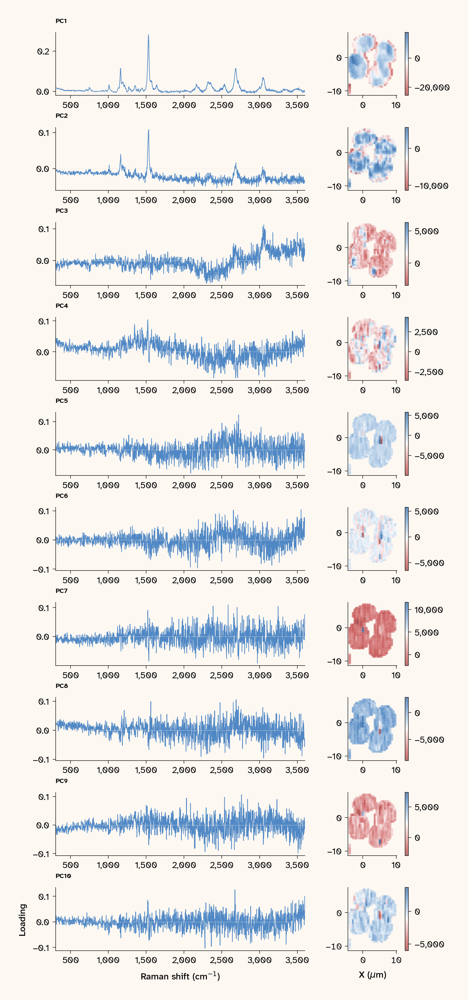

In [38]:
# | code-fold: true
# | code-summary: "Source code for this figure:"
# | label: fig-473-pca-masked
# | fig-cap: 'PCA on the masked, baseline-corrected 473 nm dataset. Left column: PC loadings for components 1–10. Right column: per-pixel scores using the same red-blue symmetric colorscale as the unmasked PCA figure. As in the unmasked figure, loading (left) and score (right) are different quantities and do not share a scale. Rows progress from PC1 (top) to PC10 (bottom). With cell-vs-background variance removed, more variance is distributed across the lower components, surfacing within-cell structure.'
# | fig-alt: "Ten-row figure of PCA results on the masked, baseline-corrected 473 nm dataset. Left column: PC loading spectra. Right column: corresponding spatial score maps with symmetric red-blue colorscale. Row labels PC1 through PC10 from top to bottom."

spectra_raw = blue_intensity_masked.values.copy()
n_spectra, n_wn = spectra_raw.shape
X_473_corrected = np.zeros_like(spectra_raw)

for i, spectrum in enumerate(spectra_raw):
    baseline, _ = airpls(spectrum, lam=1e6)
    X_473_corrected[i] = spectrum - baseline

# Clip small negatives left by baseline subtraction
X_473_corrected = np.clip(X_473_corrected, 0, None)

X_473_processed = X_473_corrected

pca_masked = PCA(n_components=10)
pc_scores_masked = pca_masked.fit_transform(X_473_processed)
pc_loadings_masked = pca_masked.components_
explained_var_masked = pca_masked.explained_variance_ratio_
for i, var in enumerate(explained_var_masked):
    print(f"  PC{i + 1}: {var * 100:.1f}%")
print(f"  Total (PC1-{len(explained_var_masked)}): {explained_var_masked.sum() * 100:.1f}%")


fig, axes = plt.subplots(
    10,
    2,
    figsize=(10, 22.2),
    layout="constrained",
    facecolor=apc.parchment,
    gridspec_kw={"width_ratios": [3, 1]},
)

for i in range(10):
    # Left column: loadings
    ax_l = axes[i, 0]
    ax_l.plot(wavenumbers_473, pc_loadings_masked[i], color=apc_473, linewidth=1)
    ax_l.axhline(0, color=apc.stone, linewidth=0.5, linestyle="--")
    ax_l.set_xlim(wavenumbers_473[0], wavenumbers_473[-1])
    ax_l.set_facecolor(apc.parchment)
    ax_l.grid(False)
    ax_l.set_title(f"PC{i + 1}", loc="left", fontweight="bold", fontsize=11)
    if i == 9:
        ax_l.set_ylabel("Loading")
        ax_l.set_xlabel("Raman shift (cm$^{-1}$)")

    # Right column: spatial maps
    ax_s = axes[i, 1]
    scatter = ax_s.scatter(
        blue_xy_masked["x_pos"],
        blue_xy_masked["y_pos"],
        c=pc_scores_masked[:, i],
        cmap=apc.gradients.red_blue.to_mpl_cmap(),
        s=20,
        alpha=0.7,
    )
    plt.colorbar(scatter, ax=ax_s, fraction=0.046, pad=0.04)
    ax_s.set_aspect("equal")
    ax_s.set_facecolor(apc.parchment)
    if i == 9:
        ax_s.set_xlabel("X ($\\mu$m)")

apc.mpl.style_plot(monospaced_axes="both")
plt.show()

PCA loadings can be positive or negative, so a loading pattern represents a spectral contrast (regions that go up when other regions go down) rather than an additive chemical signal. This makes direct interpretation less straightforward than NMF: a component with strong loadings at carotenoid wavenumbers (~1157, ~1530 cm⁻¹) may reflect carotenoid-enriched vs. carotenoid-depleted pixels, not carotenoid abundance alone. The spatial maps should be read with this in mind: the red-blue colorscale is symmetric around zero, with red indicating pixels that score positively on the component and blue indicating pixels that score negatively.

Looking at the masked PCA components: PC1 explains the largest single fraction of within-cell variance (~26.7%), with PC2–PC10 each contributing smaller fractions (PC1-10 total: ~37.3%; see the cell output for exact values). Its spatial map separates the chloroplast moderately well, although the boundary between chloroplast and surrounding cytoplasm is not sharp. PC3 again shows a small, localized hotspot at the edge of the chloroplast-like region, similar to the eyespot-like feature in unmasked PC2/PC3 — the fact that this feature is present in both decompositions makes it more plausibly real than an artifact of preprocessing choices. PC2 and PC4 show broader spatial gradients without an obvious organelle correspondence. The remaining components (PC5–PC10) have low-amplitude, noisy spectral patterns and unstructured spatial maps, consistent with capturing measurement noise.

#### NMF spectral decomposition

NMF is applied to the same preprocessed masked dataset used for masked PCA above (airPLS baseline-corrected, negatives clipped). We fit 10 components, chosen by inspection — enough to capture spectrally distinct features beyond the dominant carotenoid signal without forcing decomposition of noise, and all shown in @fig-473-nmf-components. Unlike PCA, NMF components have no inherent ordering: they are not ranked by explained variance, and component numbering is arbitrary. Components are evaluated by visual inspection of their spectra and spatial maps, looking for fingerprint-region peaks and spatially coherent patterns.

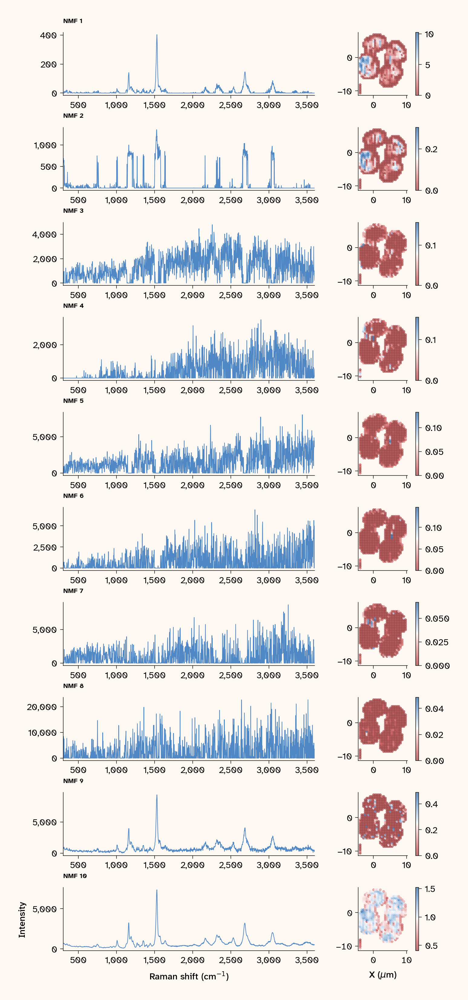

In [39]:
# | code-fold: true
# | code-summary: "Source code for this figure:"
# | label: fig-473-nmf-components
# | fig-cap: "NMF decomposition of the masked, baseline-corrected 473 nm dataset into 10 components. Left column: non-negative component spectra (representing additive spectral contributions). Right column: per-pixel abundance maps for each component. The component spectrum (left, y-axis) and abundance map (right, colorbar) are both non-negative but on different scales: the spectrum shows the additive spectral contribution per wavenumber while the abundance map shows how much of each component is present at each spatial location. Rows progress from NMF 1 (top) to NMF 10 (bottom). Unlike PCA, NMF loadings are non-negative by construction, so the maps show only magnitude."
# | fig-alt: "Ten-row figure of NMF decomposition of the masked, baseline-corrected 473 nm dataset. Left column: non-negative component spectra. Right column: per-pixel abundance maps. Row labels NMF 1 through NMF 10 from top to bottom."

# NMF on the same masked, baseline-corrected, non-negative-clipped data used for masked PCA
# X_473_processed is already non-negative (clipped) so no further shift needed.

# Fit NMF with 10 components
n_components_nmf = 10
nmf_473 = NMF(
    n_components=n_components_nmf,
    init="nndsvda",
    random_state=42,
    max_iter=2000,
)
nmf_scores_473 = nmf_473.fit_transform(X_473_processed)
nmf_components_473 = nmf_473.components_

n_show = 10
fig, axes = plt.subplots(
    n_show,
    2,
    figsize=(10, 22.2),
    layout="constrained",
    facecolor=apc.parchment,
    gridspec_kw={"width_ratios": [3, 1]},
)

for i in range(n_show):
    ax_l = axes[i, 0]
    ax_l.plot(wavenumbers_473, nmf_components_473[i], color=apc_473, linewidth=1)
    ax_l.set_xlim(wavenumbers_473[0], wavenumbers_473[-1])
    ax_l.set_facecolor(apc.parchment)
    ax_l.grid(False)
    ax_l.set_title(f"NMF {i + 1}", loc="left", fontweight="bold", fontsize=11)
    if i == n_show - 1:
        ax_l.set_ylabel("Intensity")
        ax_l.set_xlabel("Raman shift (cm$^{-1}$)")

    ax_s = axes[i, 1]
    scatter = ax_s.scatter(
        blue_xy_masked["x_pos"],
        blue_xy_masked["y_pos"],
        c=nmf_scores_473[:, i],
        cmap=apc.gradients.red_blue.to_mpl_cmap(),
        s=20,
        alpha=0.7,
    )
    plt.colorbar(scatter, ax=ax_s, fraction=0.046, pad=0.04)
    ax_s.set_aspect("equal")
    ax_s.set_facecolor(apc.parchment)
    if i == n_show - 1:
        ax_s.set_xlabel("X ($\\mu$m)")

apc.mpl.style_plot(monospaced_axes="both")
plt.show()

Examining the 10 components, 6 appear to be noise with flat spatial distributions; these likely represent instrumental background or residual fluorescence not fully removed by baseline correction.

A subset of components stand out by having coherent fingerprint-region spectra and non-uniform spatial maps. Components with strong peaks at ~1157 and ~1530 cm⁻¹ (the ν₂ C-C stretch and ν₁ C=C stretch modes of carotenoids) are of particular interest. Components 1 and 2 show a localized structure whose spatial map concentrates in a cup shape taking up about half the cell, consistent with the chloroplast, which contains carotenoids and chlorophyll. Component 10 has a similar pattern but more diffuse. It is possible the eyespot, a β-carotene-rich organelle known to produce a strong, spatially confined resonance-enhanced signal under 473 nm excitation [@kubo2000eyespot], is also being picked up in these maps.

This interpretation is tentative: confirming the eyespot assignment would require a co-registered brightfield or fluorescence image of the same cells. The beam size (~1 μm) is comparable to the eyespot diameter, so one or two bright points in the spatial map could reflect a genuine localized structure or local intensity variation.

### Comparing approaches: univariate, PCA, and NMF

@fig-method-comparison maps the carotenoid signal at ~1530 cm⁻¹ using three methods on the same masked, baseline-corrected 473 nm dataset: a simple univariate intensity lookup, the masked PCA component with the highest loading at 1530 cm⁻¹, and the NMF component with the highest spectral weight at 1530 cm⁻¹. The two decomposition methods use slightly different selection criteria here: for PCA, we pick the component with the largest absolute loading at 1530 cm⁻¹ (PCA loadings can be positive or negative, so absolute value is the natural measure of "how much carotenoid"); for NMF, we pick the component with the highest signal-to-noise ratio at 1530 cm⁻¹, using the silent region 2000–2100 cm⁻¹ as the noise reference (NMF components are non-negative, so a high raw value alone could just be a noisy component — SNR filters that out). Each panel uses its own symmetric red-blue colorscale, because the three methods produce values on very different numerical scales, so a shared range would compress most panels. Within each panel, red indicates above-average signal and blue indicates below-average.


Most carotenoid-correlated PC (masked): PC1
Best NMF component at 1530 cm⁻¹ by SNR: component 2 (SNR=1885.7)


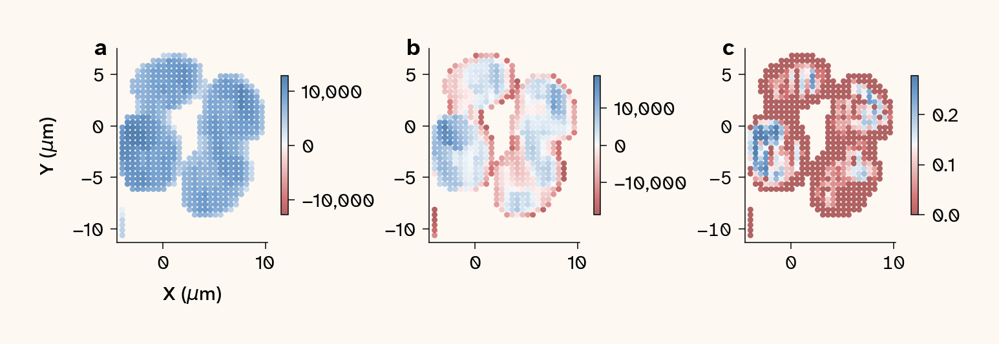

In [40]:
# | code-fold: true
# | code-summary: "Source code for this figure:"
# | label: fig-method-comparison
# | fig-cap: 'Three approaches to mapping the carotenoid signal at ~1530 cm⁻¹ on the same masked, baseline-corrected 473 nm dataset. (a) Univariate intensity at 1530 cm⁻¹ (sequential colorscale). (b) PCA component most strongly correlated with the 1530 cm⁻¹ loading (symmetric red-blue scale). (c) NMF component with the highest signal-to-noise ratio at 1530 cm⁻¹ (0-to-max scale; silent region 2000–2100 cm⁻¹ as noise reference).'
# | fig-alt: "Three-panel figure comparing methods for mapping the carotenoid signal at ~1530 cm⁻¹. (a) Univariate intensity at 1530 cm⁻¹. (b) PCA component most correlated with the 1530 cm⁻¹ loading. (c) NMF component with the highest signal-to-noise ratio at 1530 cm⁻¹."

# --- Univariate: intensity at ~1530 cm⁻¹ from baseline-corrected data ---
target_wn = 1530
idx_1530 = np.argmin(np.abs(wavenumbers_473 - target_wn))
univariate_map = X_473_processed[:, idx_1530]

# --- Masked PCA: PC most correlated with 1530 cm⁻¹ loading ---
loadings_at_1530 = np.abs(pc_loadings_masked[:, idx_1530])
best_pc = np.argmax(loadings_at_1530)
pca_map = pc_scores_masked[:, best_pc]
print(f"Most carotenoid-correlated PC (masked): PC{best_pc + 1}")

# --- NMF: component with highest SNR at 1530 cm⁻¹ ---
# SNR = intensity at 1530 / std(silent region 2000-2100 cm⁻¹)
# This avoids selecting noisy components that happen to have high raw intensity at 1530.
silent_mask = (wavenumbers_473 >= 2000) & (wavenumbers_473 <= 2100)
snr_at_1530 = np.array(
    [
        nmf_components_473[i, idx_1530] / (nmf_components_473[i, silent_mask].std() + 1e-10)
        for i in range(n_components_nmf)
    ]
)
best_nmf = np.argmax(snr_at_1530)
nmf_map = nmf_scores_473[:, best_nmf]
print(
    f"Best NMF component at 1530 cm⁻¹ by SNR: component {best_nmf + 1} (SNR={snr_at_1530[best_nmf]:.1f})"
)

# Each panel uses its own symmetric colorscale — the three methods operate
# on different numerical scales so a shared range would compress most panels.
fig, axes = plt.subplots(1, 3, figsize=(10, 3.3), layout="constrained", facecolor=apc.parchment)
cmap = apc.gradients.red_blue.to_mpl_cmap()

panel_labels = ["a", "b", "c"]
for j, (ax, data) in enumerate(zip(axes, [univariate_map, pca_map, nmf_map], strict=True)):
    if j == 2:  # NMF scores are non-negative; use full positive range
        vmin_val = 0
        vmax_val = np.percentile(data, 99)
    else:
        vmax_val = np.percentile(np.abs(data), 99)
        vmin_val = -vmax_val
    sc = ax.scatter(
        blue_xy_masked["x_pos"],
        blue_xy_masked["y_pos"],
        c=data,
        cmap=cmap,
        vmin=vmin_val,
        vmax=vmax_val,
        s=20,
        alpha=0.8,
    )
    plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
    ax.set_aspect("equal")
    ax.set_facecolor(apc.parchment)
    ax.text(
        -0.15,
        1.05,
        panel_labels[j],
        transform=ax.transAxes,
        fontsize=18,
        fontweight="bold",
        va="top",
    )
    if j == 0:
        ax.set_xlabel("X ($\\mu$m)")
        ax.set_ylabel("Y ($\\mu$m)")

apc.mpl.style_plot(monospaced_axes="both")
plt.show()

The univariate map shows intensity at exactly one wavenumber, bright wherever carotenoids are present, which includes the whole cell body. The masked PCA map shows scores for the component most correlated with the 1530 cm⁻¹ loading. Because PCA scores are bipolar, the map captures how much each pixel deviates from the mean in the direction of carotenoid variance, not absolute carotenoid abundance. The NMF map shows the spatial abundance of the component whose spectrum most closely matches the 1530 cm⁻¹ region. Because NMF enforces non-negativity, this component represents an additive carotenoid-like signal rather than a contrast, and its spatial map tends to be sparser and more localized.




## Discussion

### What we found

Spontaneous Raman mapping of *Chlamydomonas* cells produced detectable signal from carotenoids, chlorophylls, and likely lipids at all three excitation wavelengths, although which specific peaks are clearly visible differs by wavelength. The 473 nm dataset shows by far the most peaks (carotenoid, chlorophyll, and likely lipid), many peaks visible well above the noise floor, and gives the clearest spatial data — though map density, focus, and other acquisition differences also favor this dataset (see Caveats). The 532 nm dataset shows a fair number of high-intensity peaks, mostly from carotenoids, with a few attributable to chlorophyll and at least one likely lipid. The 785 nm dataset has the weakest signal overall but shows peaks from all three molecule classes; the major carotenoid peaks are present, though minor carotenoid features that 473 nm resolves are not clearly visible. This pattern matches the predictions from the pigment-standards UV-Vis: 473 nm overlaps the carotenoid absorption maximum, 532 nm sits on the absorption tail, and 785 nm doesn't overlap at all.

The 473 nm line also overlaps the chlorophyll b Soret band, and chlorophyll peaks such as ~746 cm^-1^ are detectable but appear much weaker than the carotenoid bands. This is also what we'd expect: carotenoid resonance Raman enhancement is orders of magnitude stronger than chlorophyll's because of the long conjugated polyene chain, and *in vivo*, rapid energy transfer from chlorophyll to neighboring carotenoids in light-harvesting complexes further suppresses chlorophyll Raman scattering [@pandey2022microraman].

The three approaches each picked up something different:

- Univariate marker maps show some hotspots in the carotenoid (and less clearly the chlorophyll) panels, but these are difficult to distinguish from diffuse signal.
- PCA on unmasked data segments cells from background cleanly with PC1. PC2–PC5 reveal within-cell structure: PC2 shows a highly localized hotspot consistent with an eyespot, and PC3 shows a similar pattern at opposite polarity. PC6–10 look like noise.
- PCA on masked, baseline-corrected data separates the chloroplast moderately well in PC1, with PC3 again showing a localized eyespot-like hotspot. The remaining components are largely noise or general biomass, and PC5–10 spectra are dominated by noise.
- NMF picked out the chloroplast in multiple components (1, 2, and 10), each emphasizing different aspects (some highly structured and localized, others more diffuse and biomass-like). It did not produce a clearly eyespot-like component.

The analyses surfaced features consistent with candidate organelles, most clearly when we applied PCA and NMF. Our previous publication compared spontaneous Raman instruments using bulk spectra of *Chlamydomonas* to help guide instrument selection [@essockburns2025comparison]; bulk spectra give population averages, while mapping adds the spatial dimension at the cost of additional time. 

### What worked and what didn't

Each excitation wavelength has a different practical role, and the choice depends on the biological question. 473 nm is the strongest choice for *Chlamydomonas* and other pigmented cells: resonance enhancement amplifies the dominant carotenoid C=C and C-C stretches by orders of magnitude, and chlorophyll and likely lipid peaks are also detectable. Many peaks are clearly visible above the noise floor, giving the most chemically informative single dataset of the three. 532 nm shows a smaller set of high-intensity peaks, primarily carotenoid with a few attributable to chlorophyll and at least one likely lipid peak. It is a reasonable alternative if 473 nm is unavailable or causes fluorescence or self-absorption issues, though it conveys less chemical information than 473 nm. 785 nm offers off-resonance excitation, which does not preferentially amplify any one pigment. In our dataset, 785 nm has the weakest signal overall but still shows peaks attributable to carotenoids, chlorophylls, and lipids. The major carotenoid peaks (ν₁, ν₂) are present, though minor features such as the ν₃ mode that 473 nm resolves are not clearly visible. A trade-off specific to this wavelength is sample preparation: standard borosilicate glass slides produce substantial fluorescence at 785 nm, so Raman-grade quartz or CaF₂ slides may give better results.

At ~1 μm beam size and 0.5 μm step, the chloroplast (occupying roughly half the cell volume in *Chlamydomonas*) is resolved across many pixels per cell, sufficient to detect within-chloroplast heterogeneity. Sub-chloroplast features near the beam size are at the resolution limit; tighter focus or a smaller beam would be needed to separate them cleanly. The analysis pipeline (masking, baseline correction, univariate maps, PCA, NMF) was most informative in roughly that order. Univariate maps require knowing the target molecules and vibrational modes in advance; for untargeted exploration of cellular composition, PCA and NMF are better suited. 